<a href="https://www.kaggle.com/code/lalit7881/what-makes-a-song-viral-eda-83-25?scriptVersionId=361316194" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/vedauv/what-makes-a-song-go-viral-10000-tracks/datasheet.md
/kaggle/input/datasets/vedauv/what-makes-a-song-go-viral-10000-tracks/README.md
/kaggle/input/datasets/vedauv/what-makes-a-song-go-viral-10000-tracks/viral_songs.csv


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/vedauv/what-makes-a-song-go-viral-10000-tracks/viral_songs.csv")

In [3]:
df.head()

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


In [4]:
df.tail()

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
9995,track_09996,Track_09996,Artist_1357,Latin,2011,184,0.786,0.774,0.778,91.4,0.000,0.216,0.273,0.287,-6.35,1865425,1
9996,track_09997,Track_09997,Artist_0123,Classical,2012,165,0.463,0.381,0.631,79.0,0.943,0.000,0.215,0.178,-8.22,186073,0
9997,track_09998,Track_09998,Artist_0504,Rock,2014,242,0.567,0.842,0.611,132.1,0.384,0.124,0.203,0.344,-11.01,55762,0
9998,track_09999,Track_09999,Artist_0801,Hip-Hop,2012,165,0.815,0.901,0.569,91.2,0.124,0.000,0.125,0.061,-7.52,3710114,1
9999,track_10000,Track_10000,Artist_1393,Jazz,2025,312,0.500,0.446,0.510,101.5,0.560,0.137,0.178,0.221,-8.97,149232,0


In [5]:
df.isnull()

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9996,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9997,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9998,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [6]:
df.isnull().sum()

track_id            0
track_name          0
artist              0
genre               0
release_year        0
duration_sec        0
danceability        0
energy              0
valence             0
tempo_bpm           0
acousticness        0
instrumentalness    0
speechiness         0
liveness            0
loudness_db         0
streams             0
viral               0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.dtypes

track_id             object
track_name           object
artist               object
genre                object
release_year          int64
duration_sec          int64
danceability        float64
energy              float64
valence             float64
tempo_bpm           float64
acousticness        float64
instrumentalness    float64
speechiness         float64
liveness            float64
loudness_db         float64
streams               int64
viral                 int64
dtype: object

In [9]:
df.shape

(10000, 17)

In [10]:
df.columns

Index(['track_id', 'track_name', 'artist', 'genre', 'release_year',
       'duration_sec', 'danceability', 'energy', 'valence', 'tempo_bpm',
       'acousticness', 'instrumentalness', 'speechiness', 'liveness',
       'loudness_db', 'streams', 'viral'],
      dtype='object')

In [11]:
df.nunique()

track_id            10000
track_name          10000
artist               1987
genre                  10
release_year           16
duration_sec          299
danceability          916
energy                873
valence               873
tempo_bpm             974
acousticness          980
instrumentalness      669
speechiness           315
liveness              524
loudness_db          1460
streams              9939
viral                   2
dtype: int64

## EDA

MUSIC STREAMING DATASET - EXPLORATORY DATA ANALYSIS

Dataset Shape: (10000, 17)

First 5 Rows:


,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1



Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          10000 non-null  object 
 1   track_name        10000 non-null  object 
 2   artist            10000 non-null  object 
 3   genre             10000 non-null  object 
 4   release_year      10000 non-null  int64  
 5   duration_sec      10000 non-null  int64  
 6   danceability      10000 non-null  float64
 7   energy            10000 non-null  float64
 8   valence           10000 non-null  float64
 9   tempo_bpm         10000 non-null  float64
 10  acousticness      10000 non-null  float64
 11  instrumentalness  10000 non-null  float64
 12  speechiness       10000 non-null  float64
 13  liveness          10000 non-null  float64
 14  loudness_db       10000 non-null  float64
 15  streams           10000 non-null  int64  
 16  viral             10

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
track_id,10000,10000,track_09984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
track_name,10000,10000,Track_09984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
artist,10000,1987,Artist_0796,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genre,10000,10,Rock,1084,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,10000.0,NaN,NaN,NaN,2017.4994,4.607854,2010.0,2013.0,2018.0,2022.0,2025.0
duration_sec,10000.0,NaN,NaN,NaN,208.7768,49.967024,60.0,175.0,209.0,242.0,433.0
danceability,10000.0,NaN,NaN,NaN,0.611709,0.192612,0.0,0.482,0.624,0.753,1.0
energy,10000.0,NaN,NaN,NaN,0.651938,0.187686,0.005,0.529,0.669,0.787,1.0
valence,10000.0,NaN,NaN,NaN,0.58228,0.177984,0.0,0.459,0.582,0.703,1.0
tempo_bpm,10000.0,NaN,NaN,NaN,110.97594,19.017206,50.0,98.0,111.3,124.5,177.8



Missing Values:


,Missing Values
track_id,0
track_name,0
artist,0
genre,0
release_year,0
duration_sec,0
danceability,0
energy,0
valence,0
tempo_bpm,0



Duplicate Rows: 0

Dataset Shape After Removing Duplicates: (10000, 17)

No missing values found.


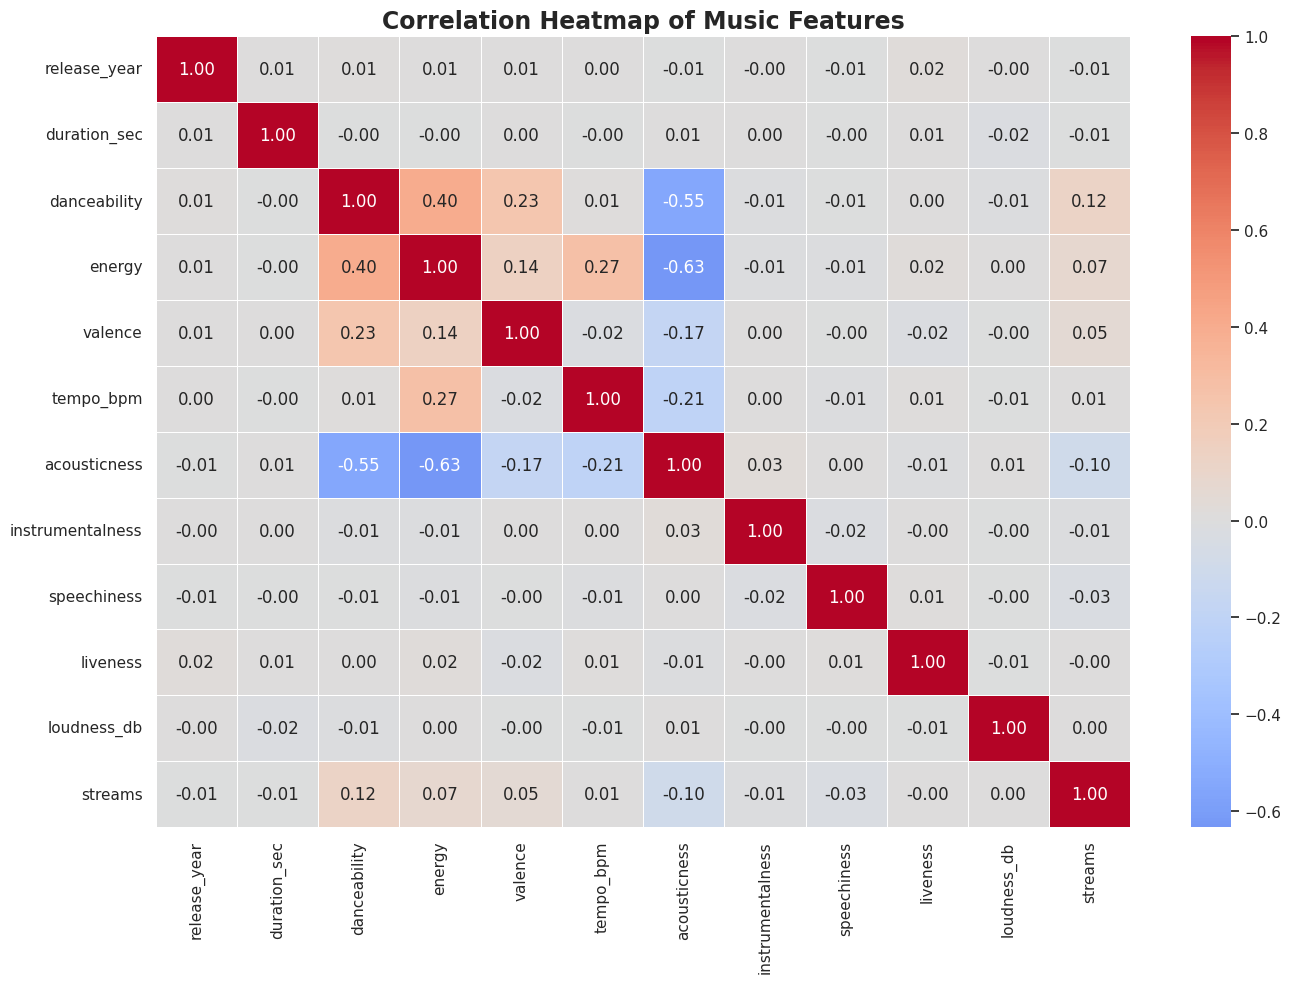

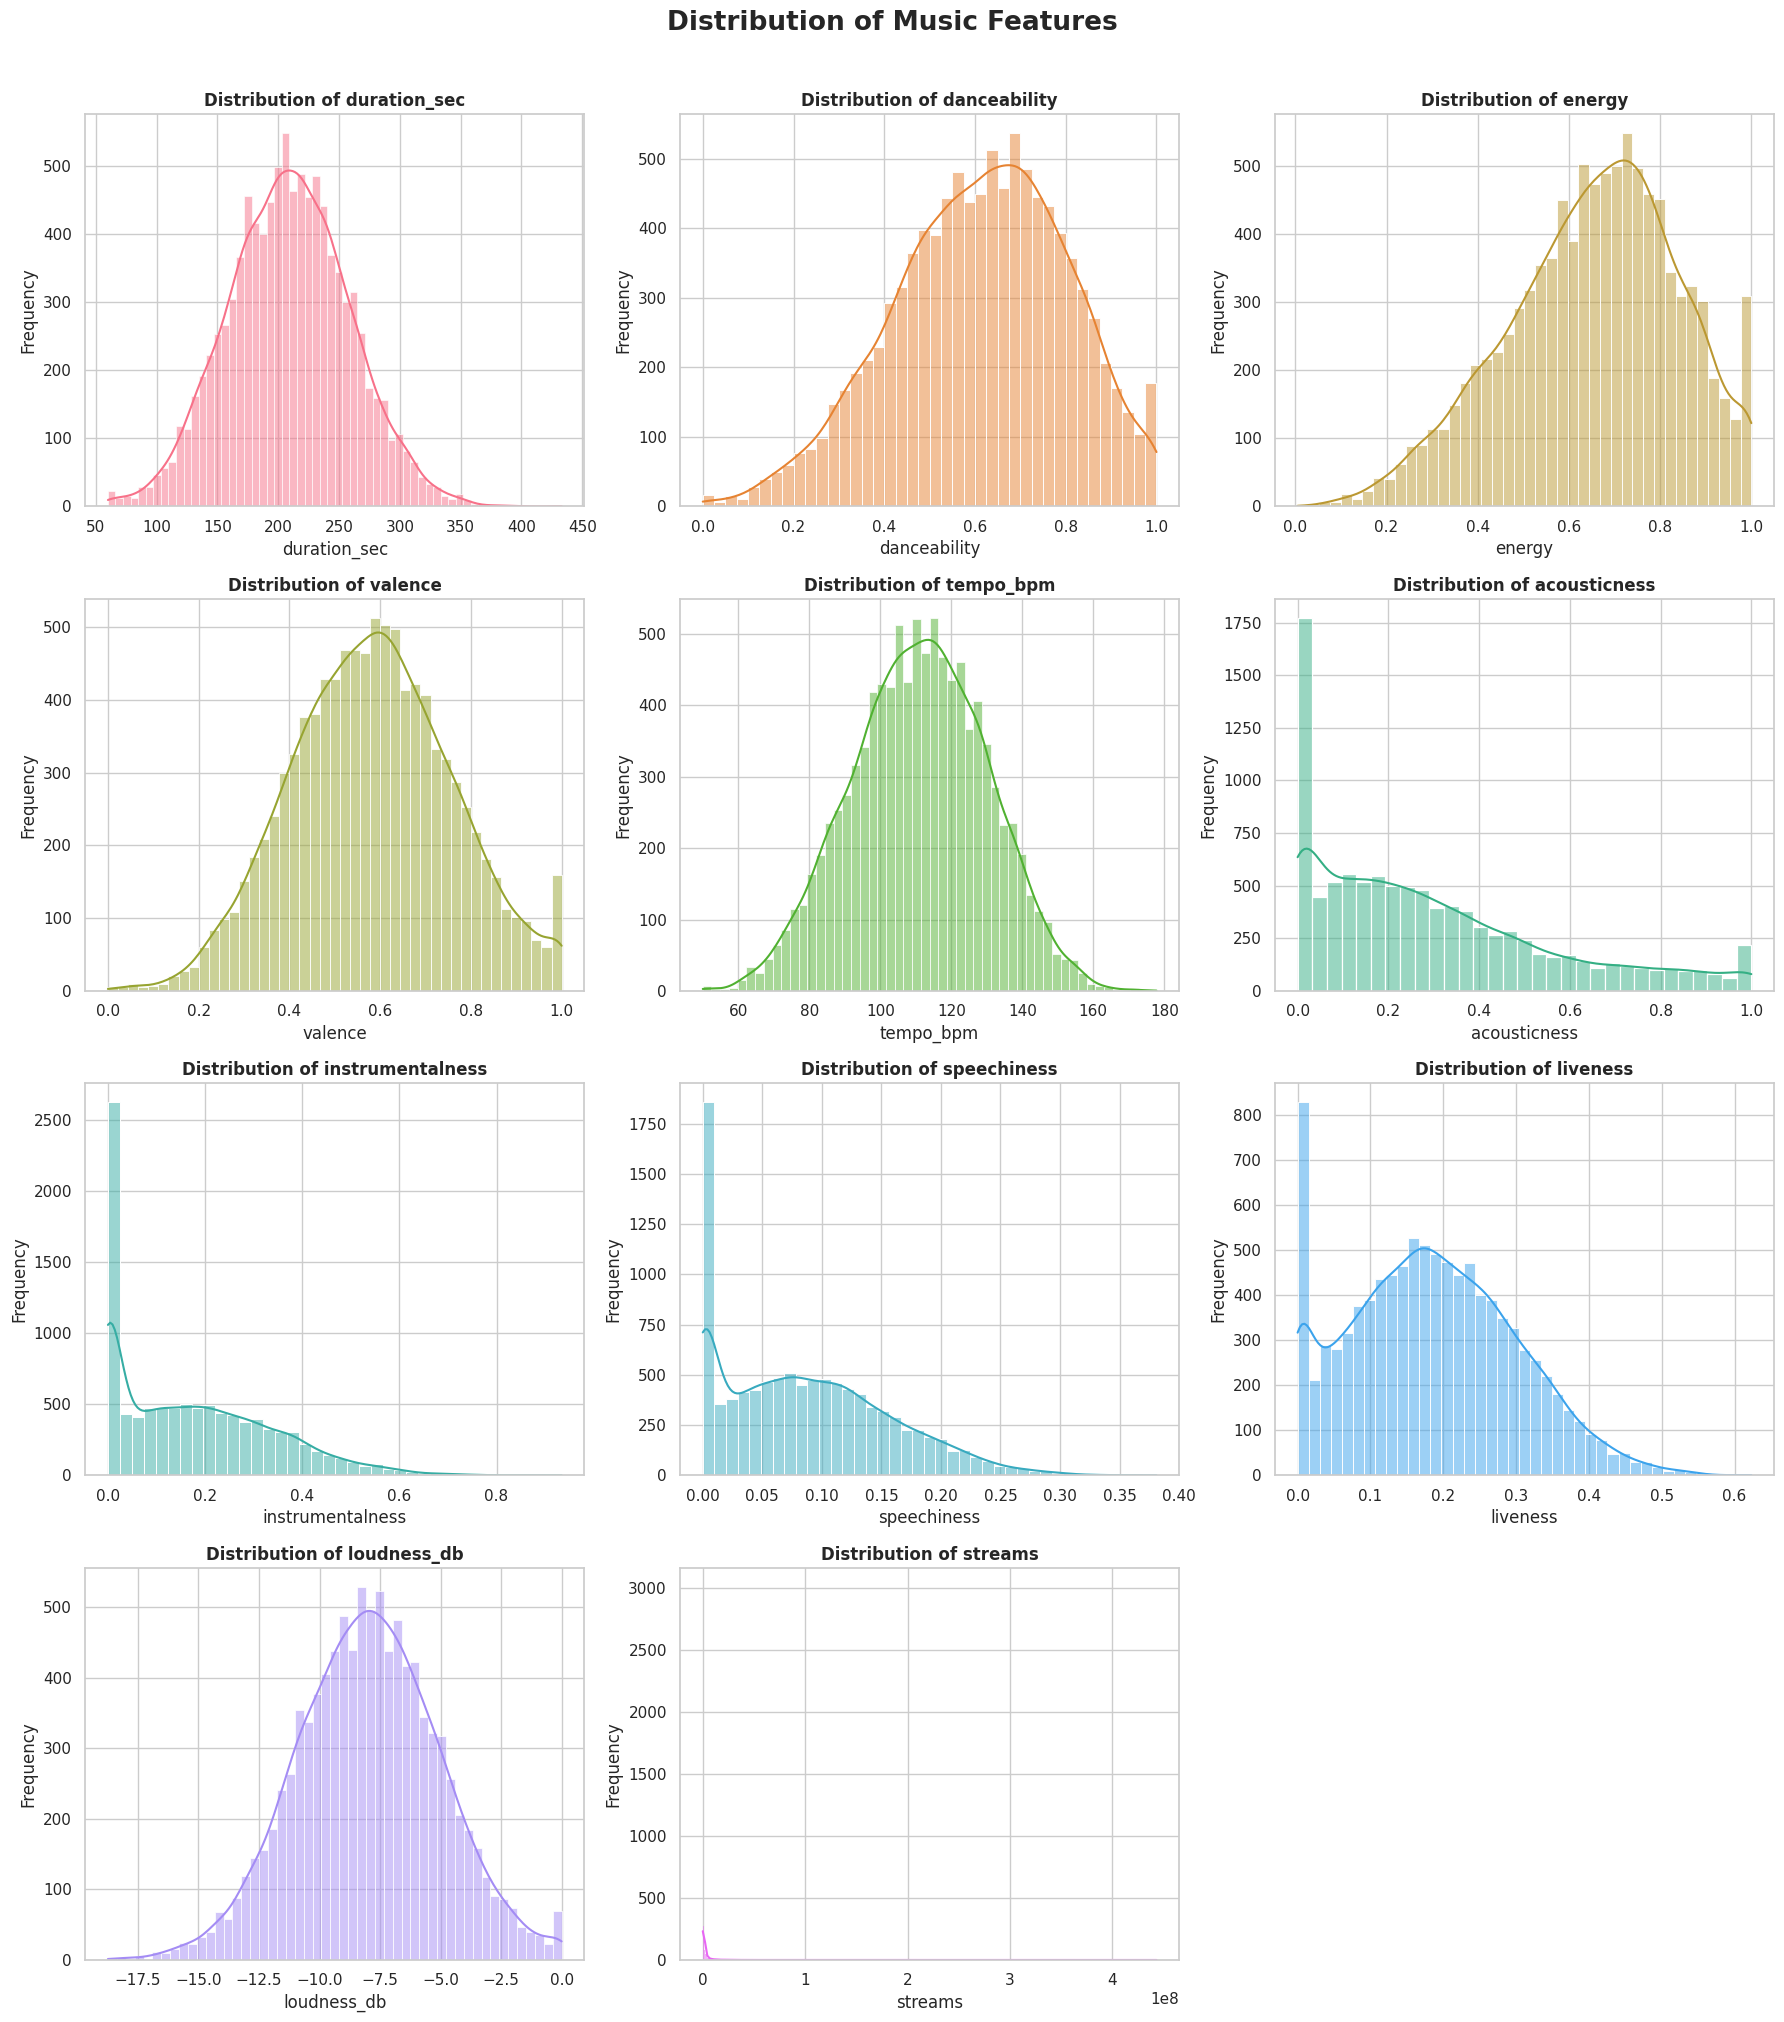

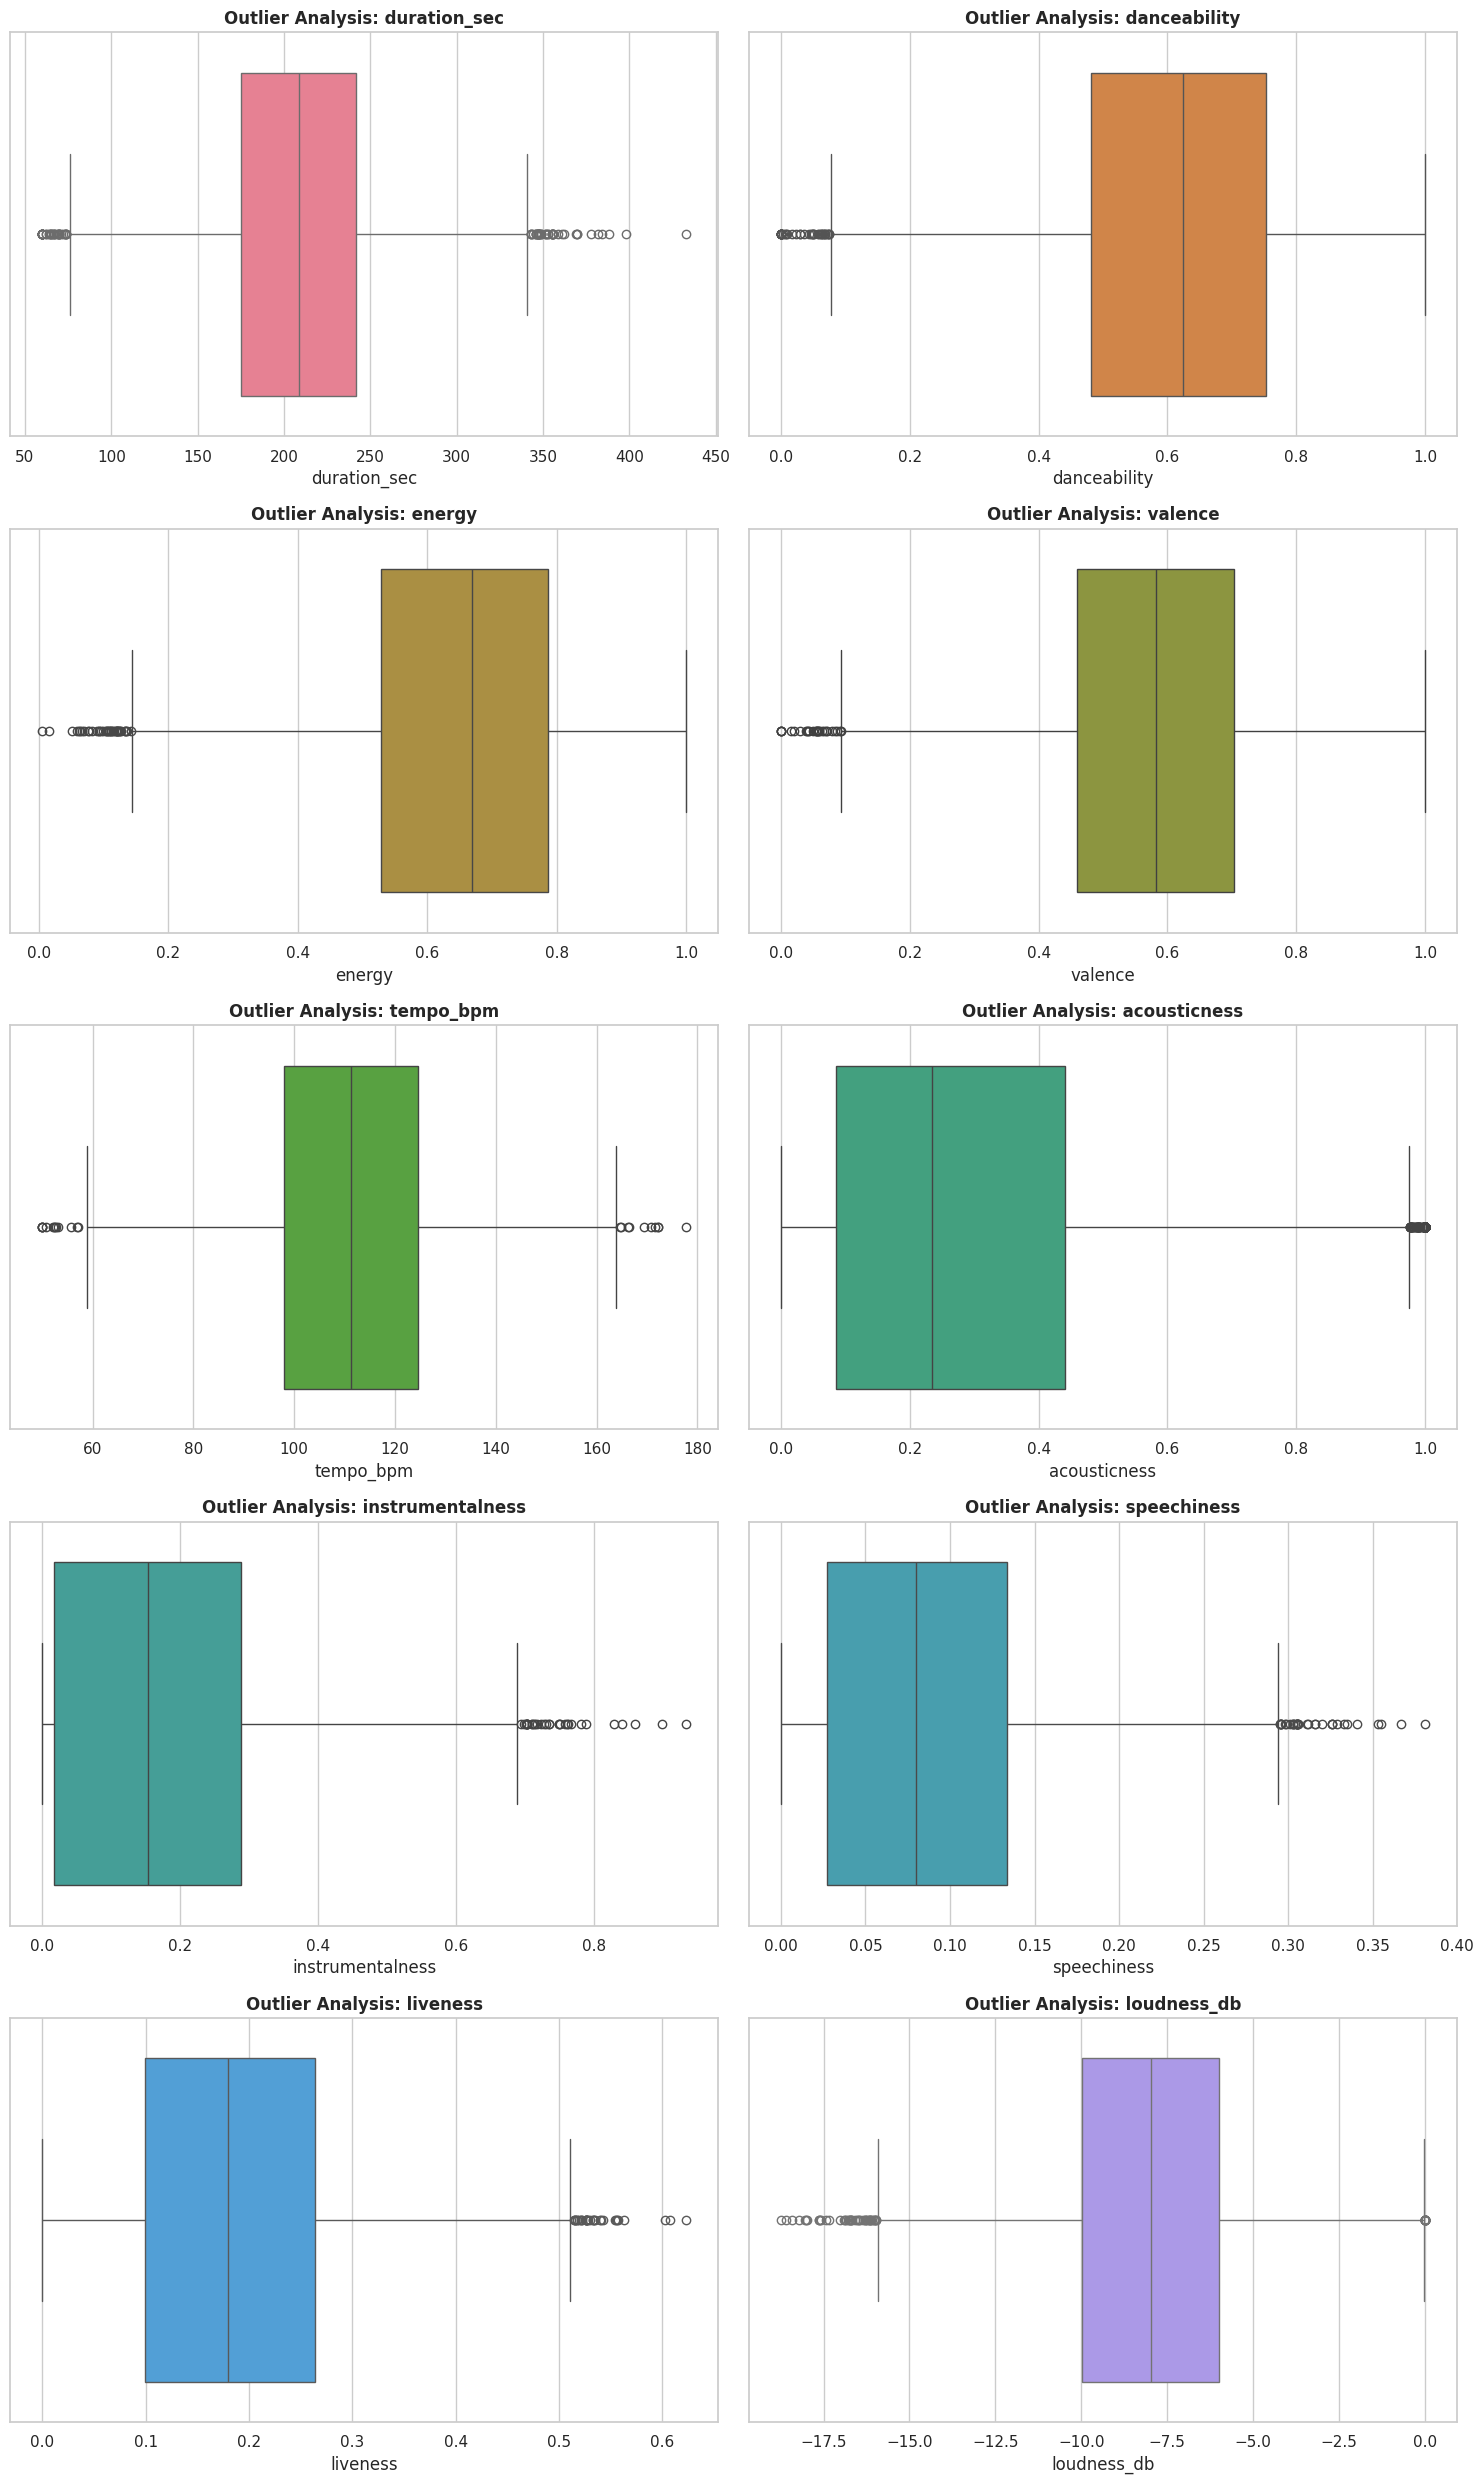

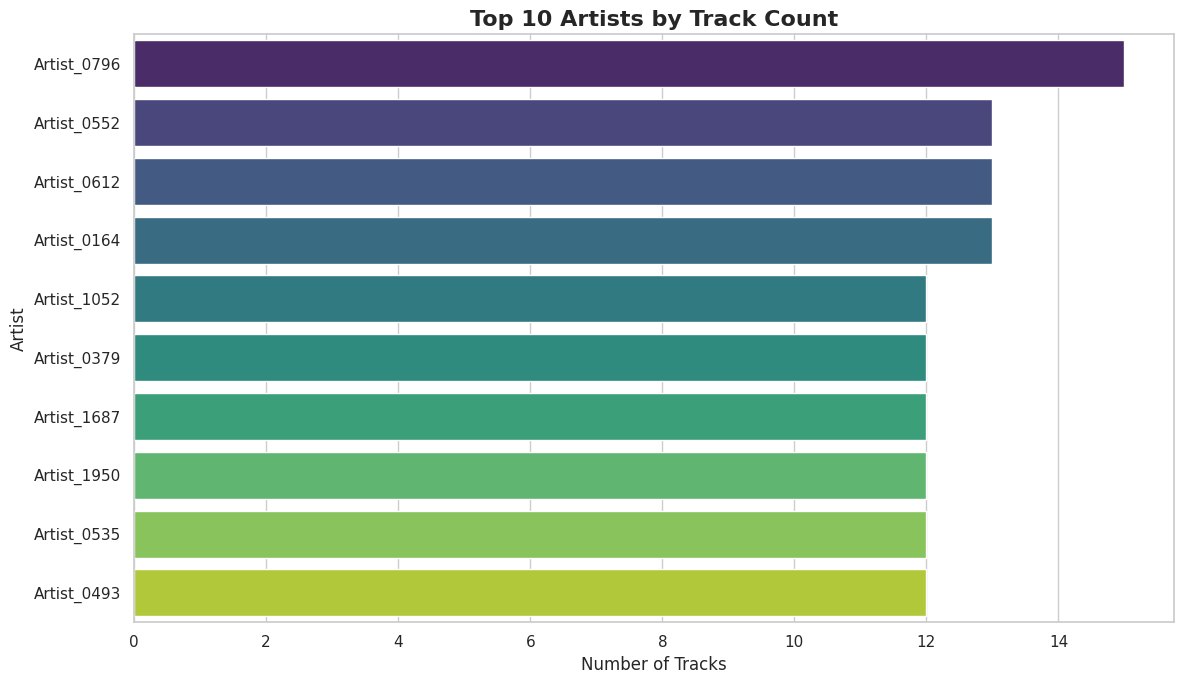

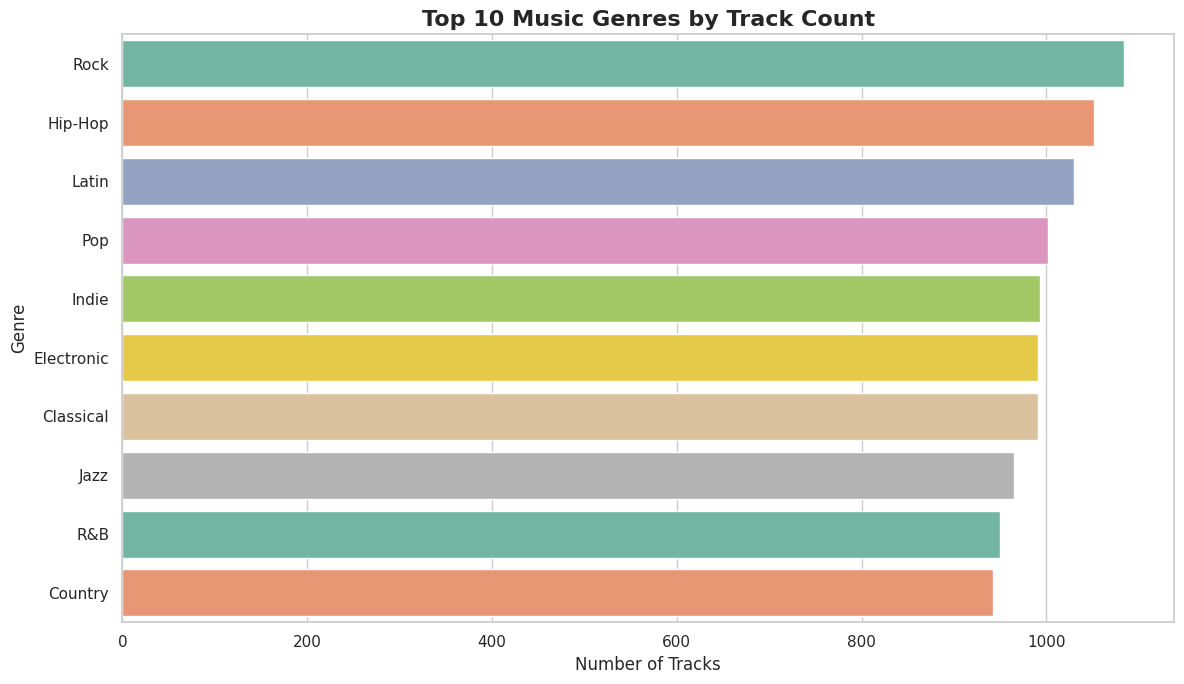

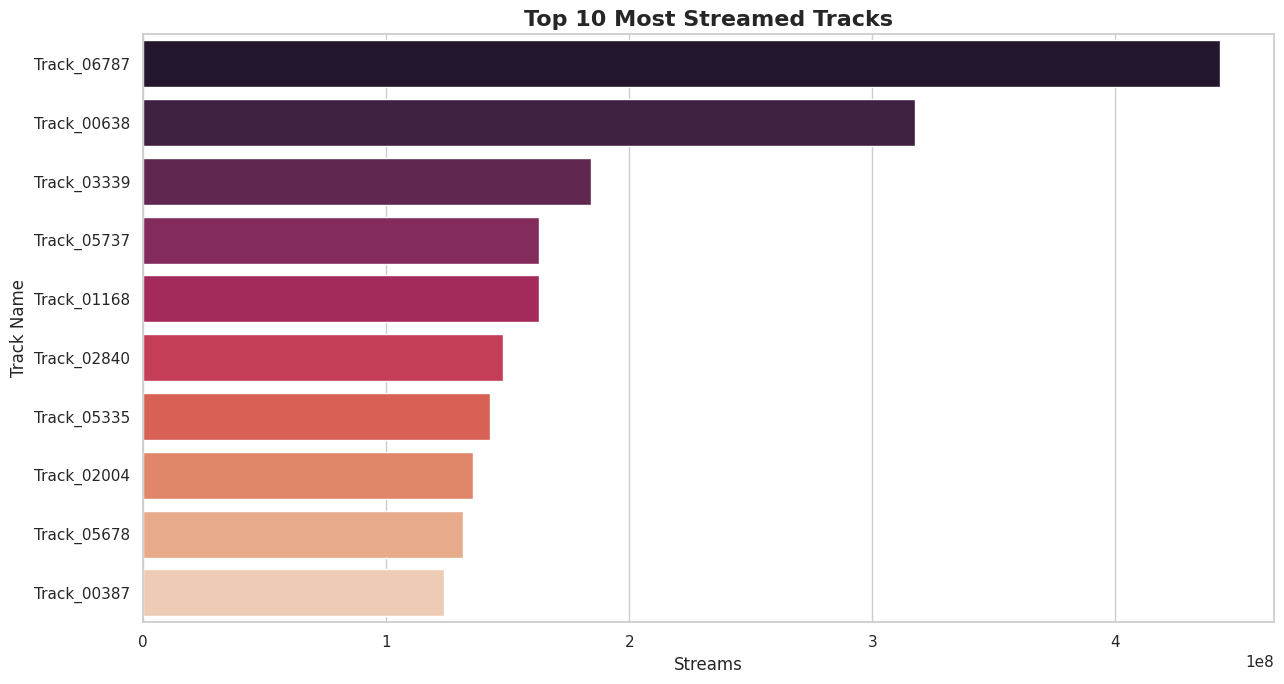

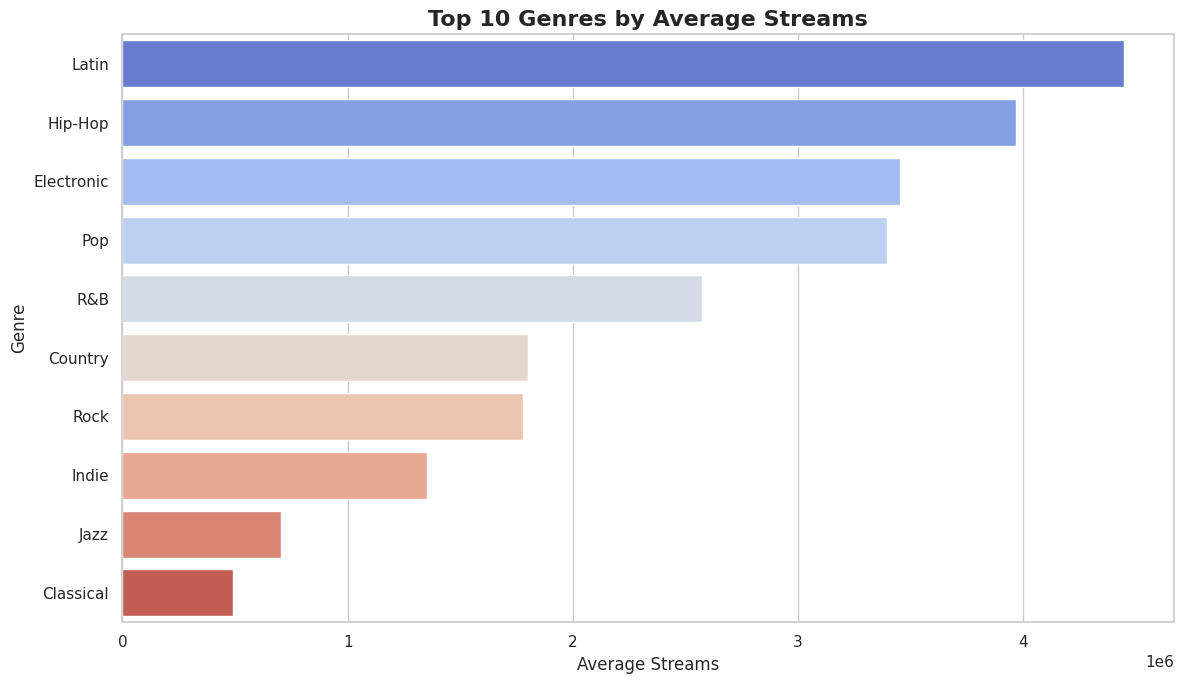

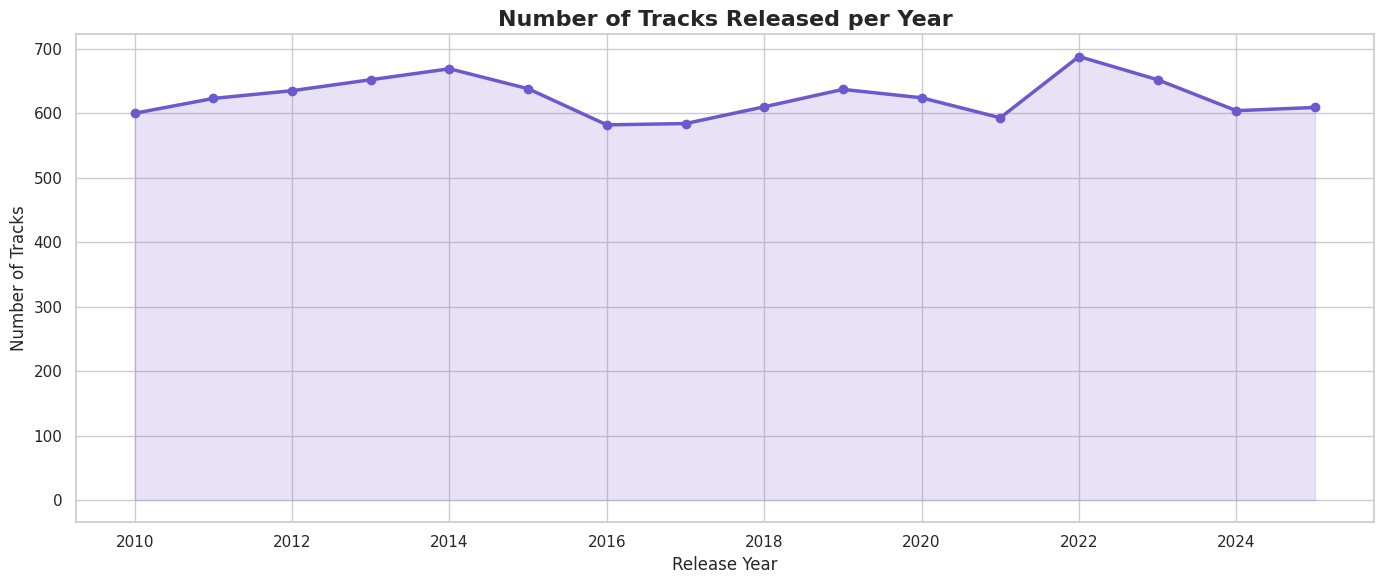

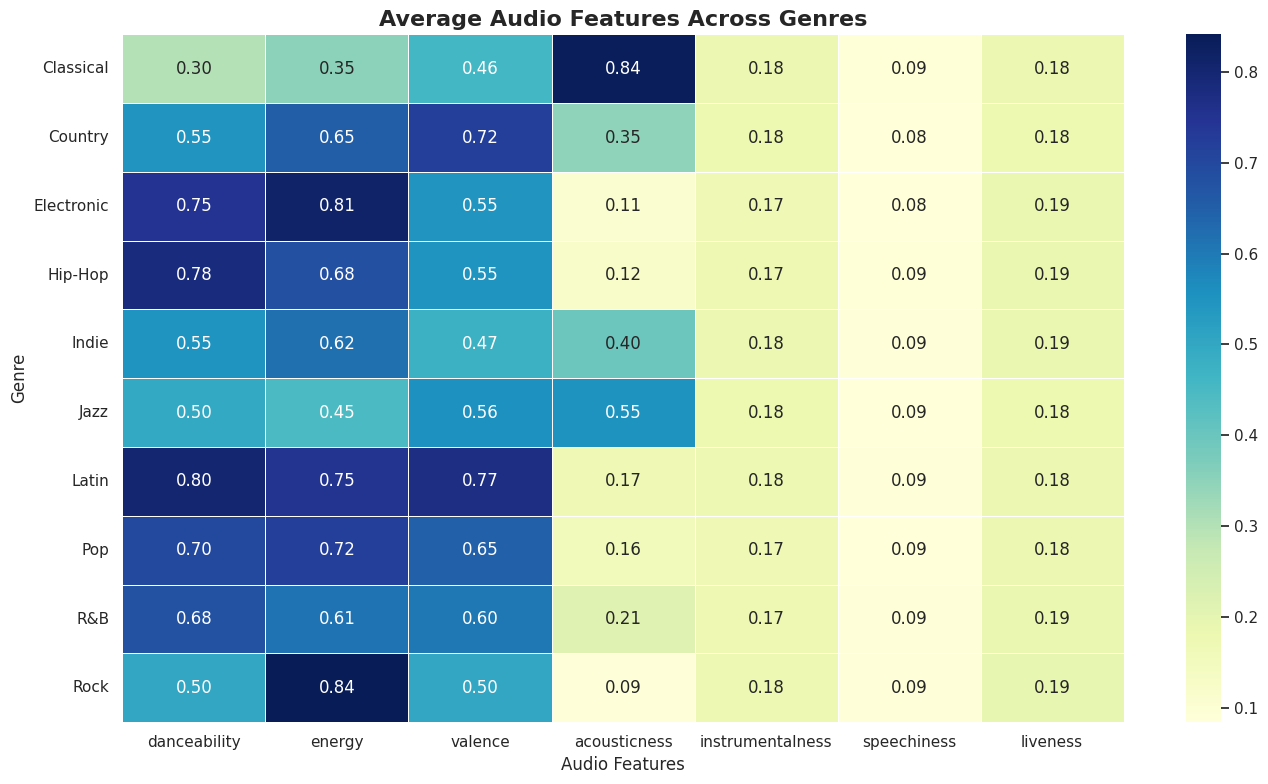

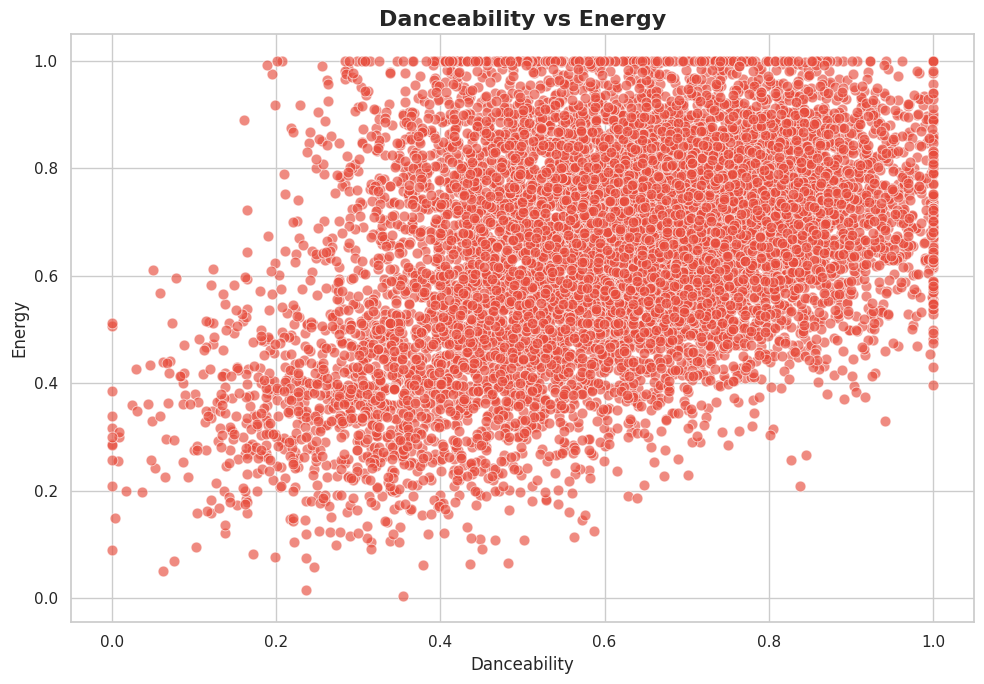

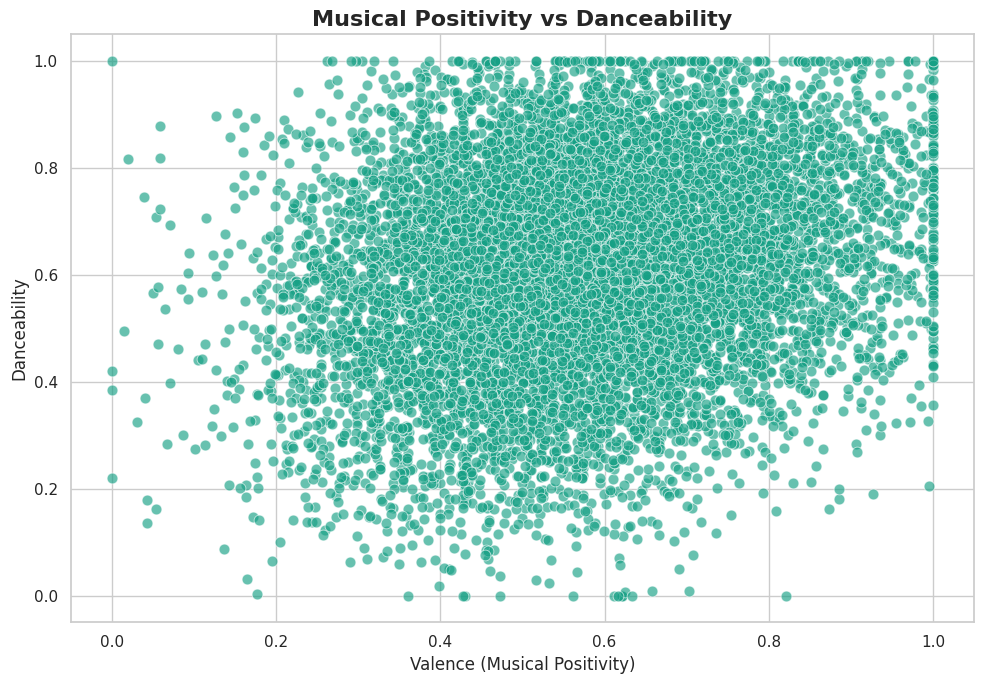

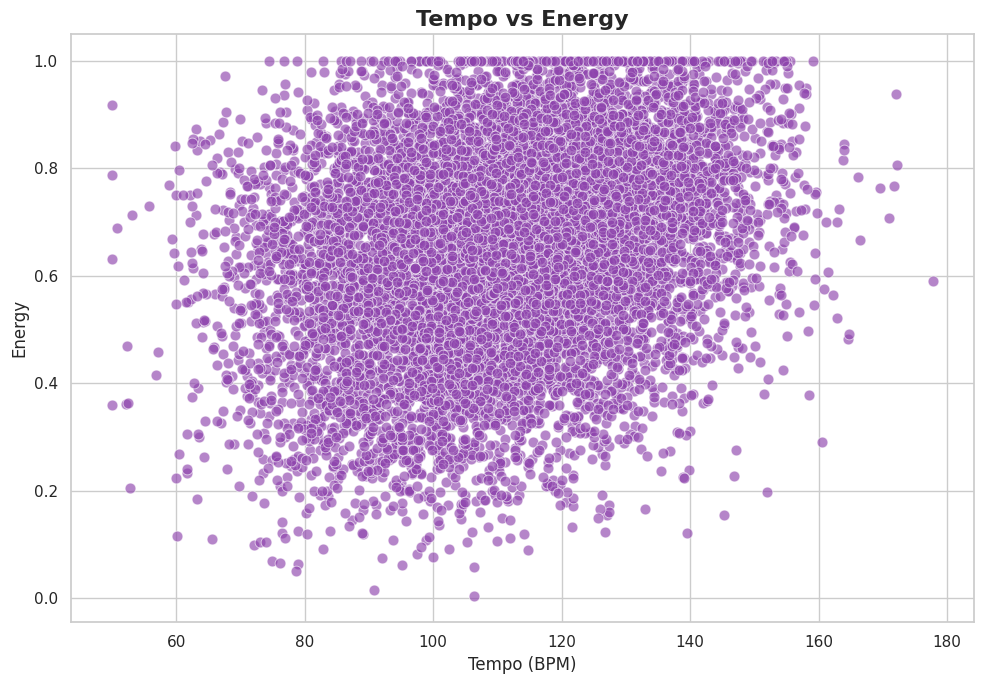

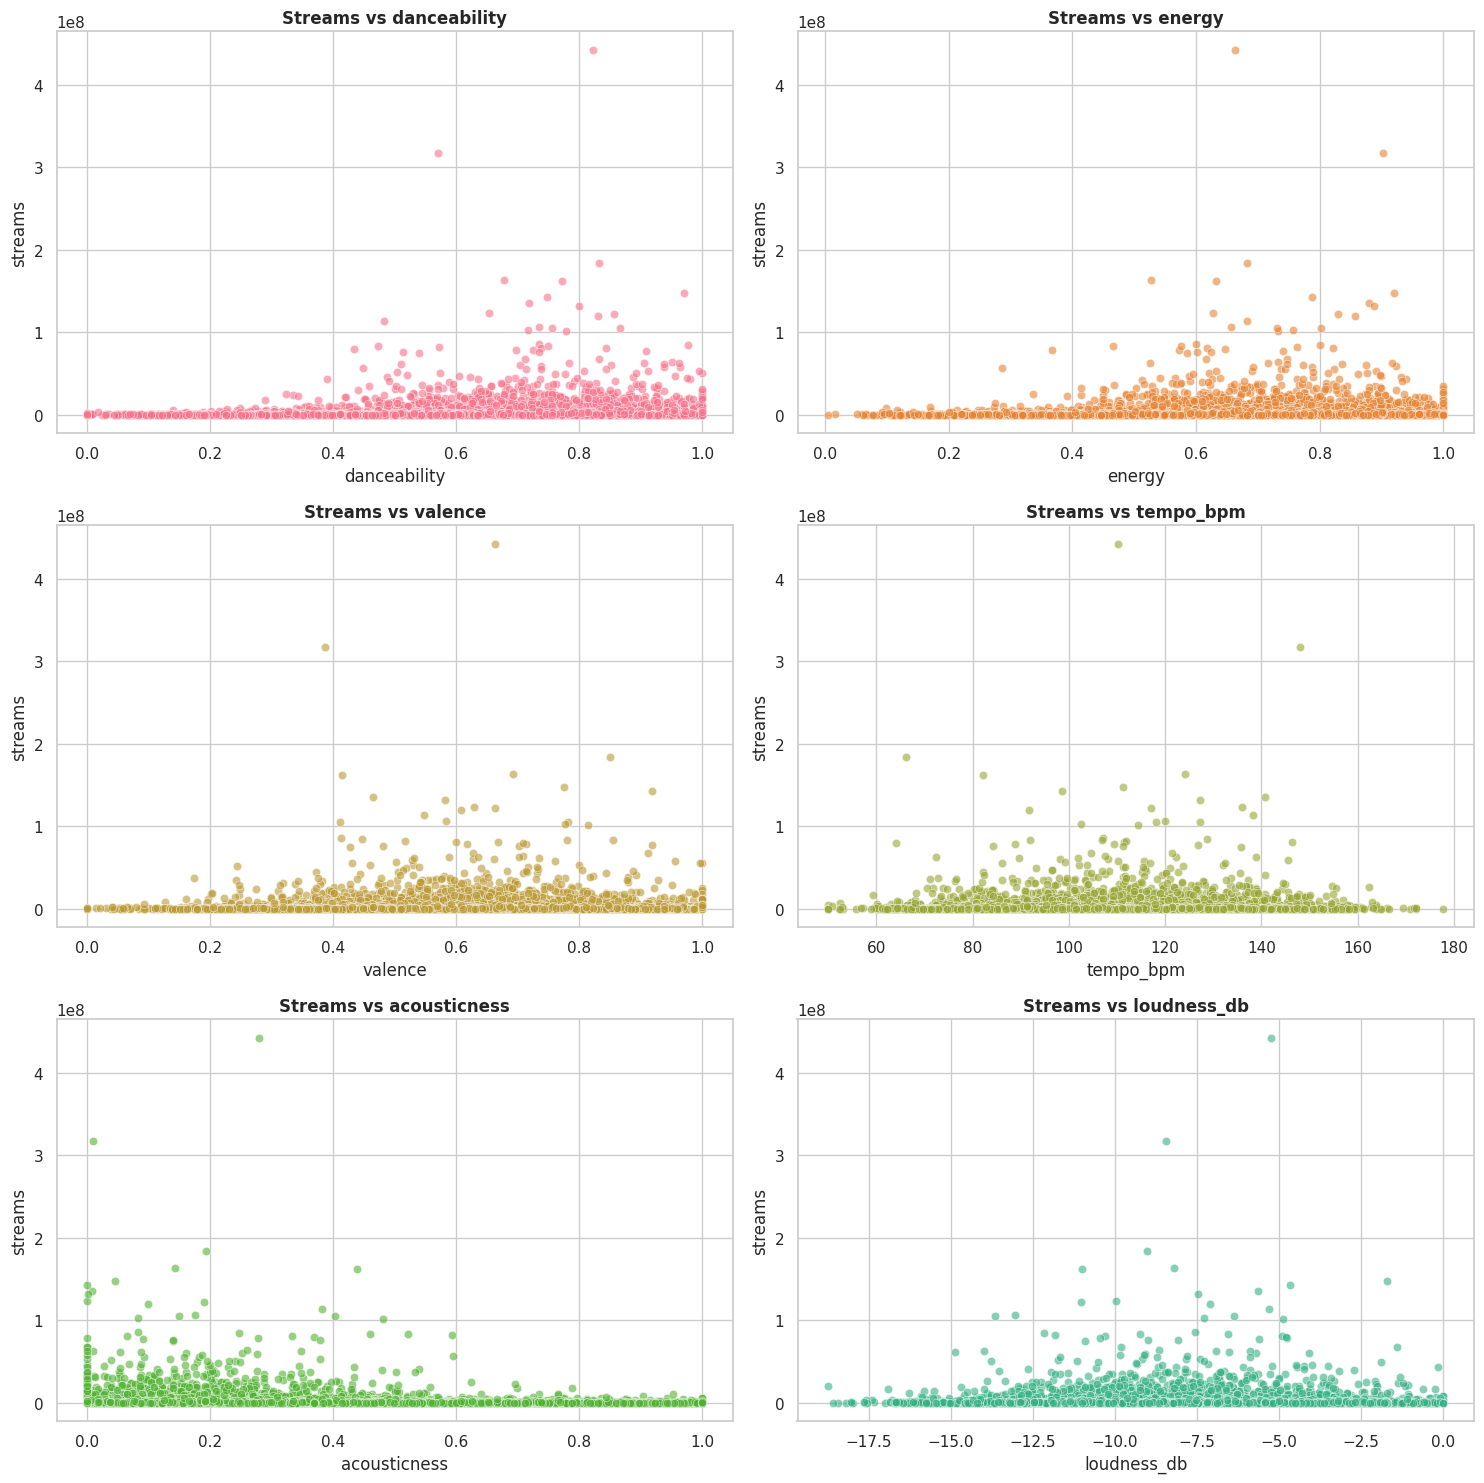

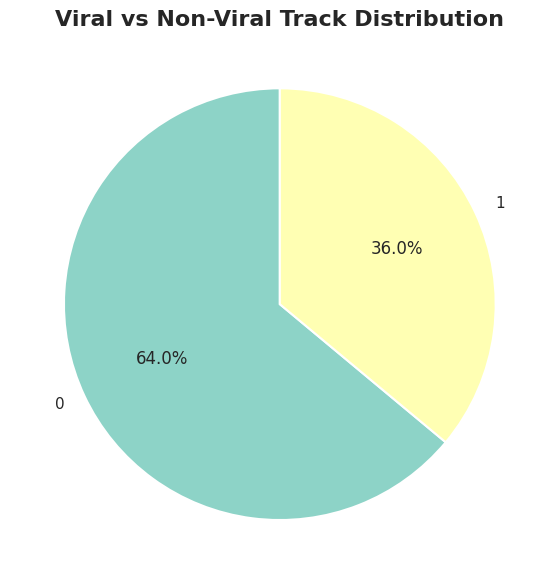

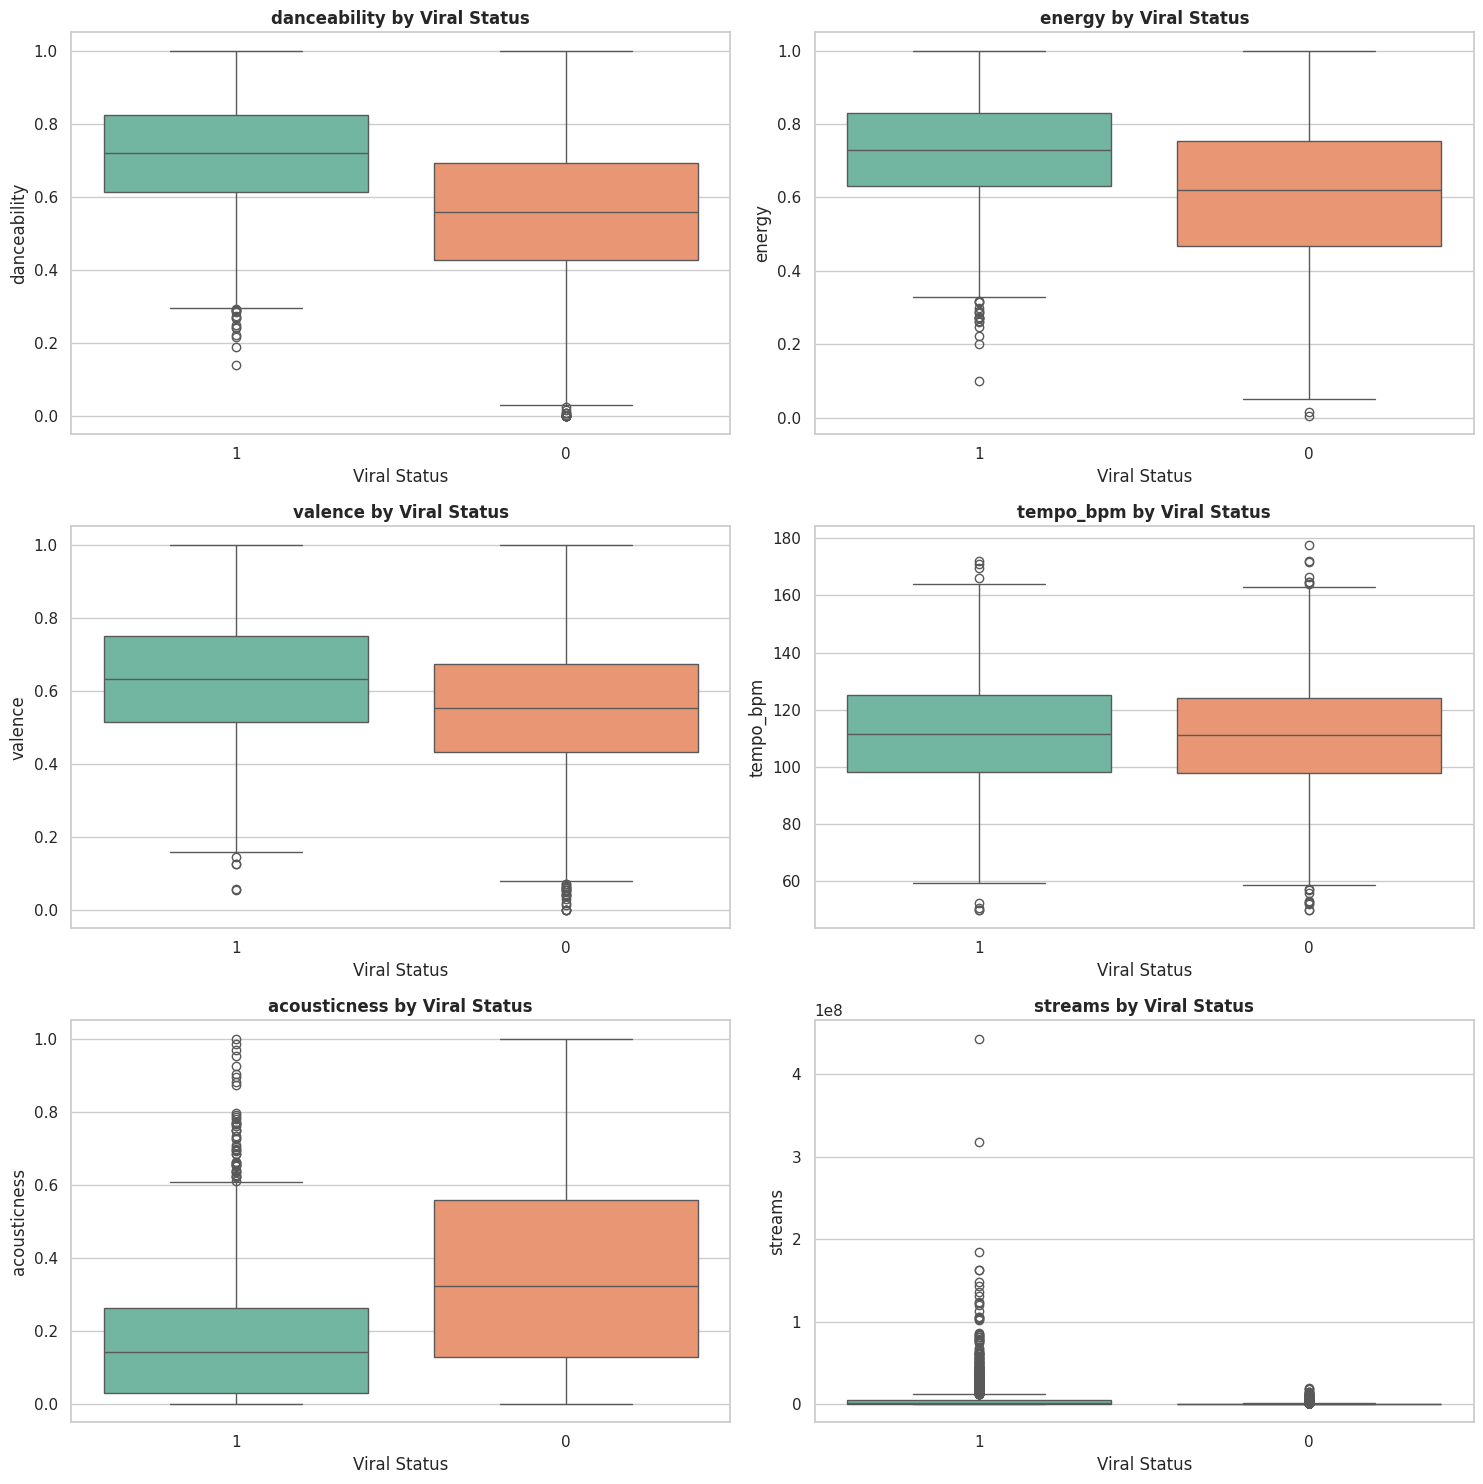

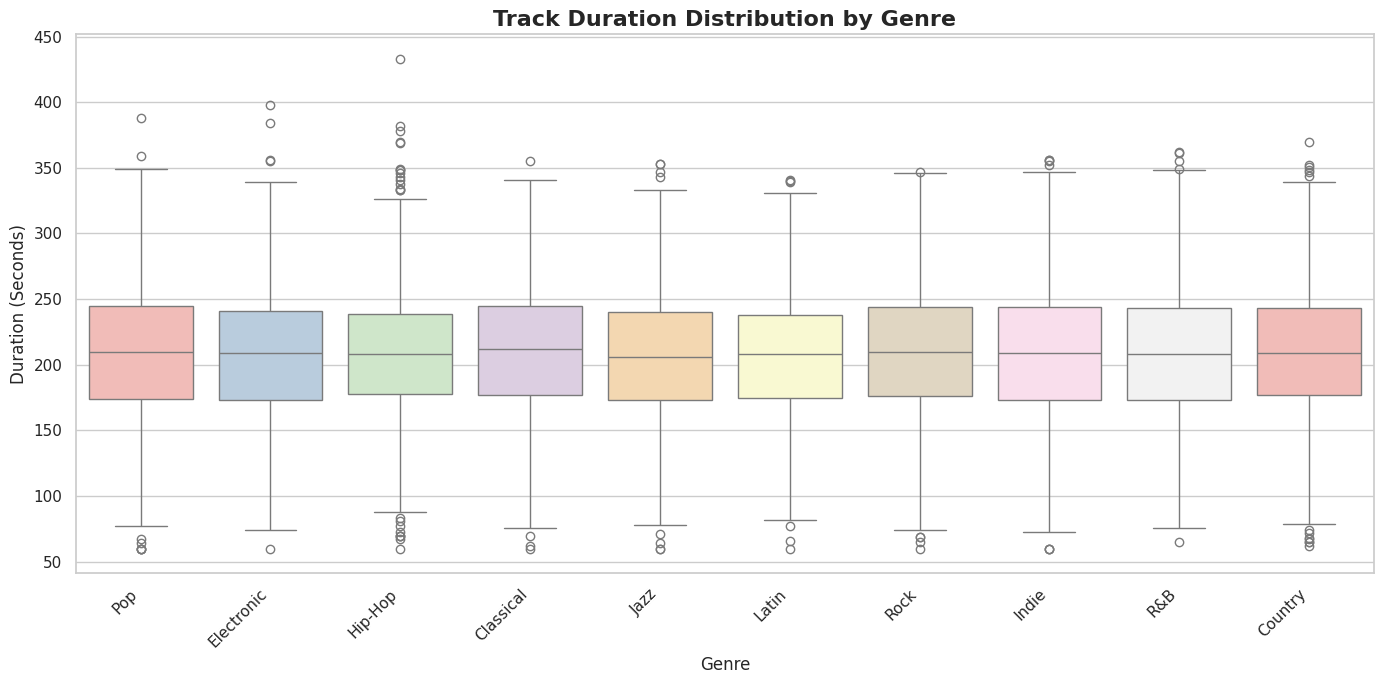

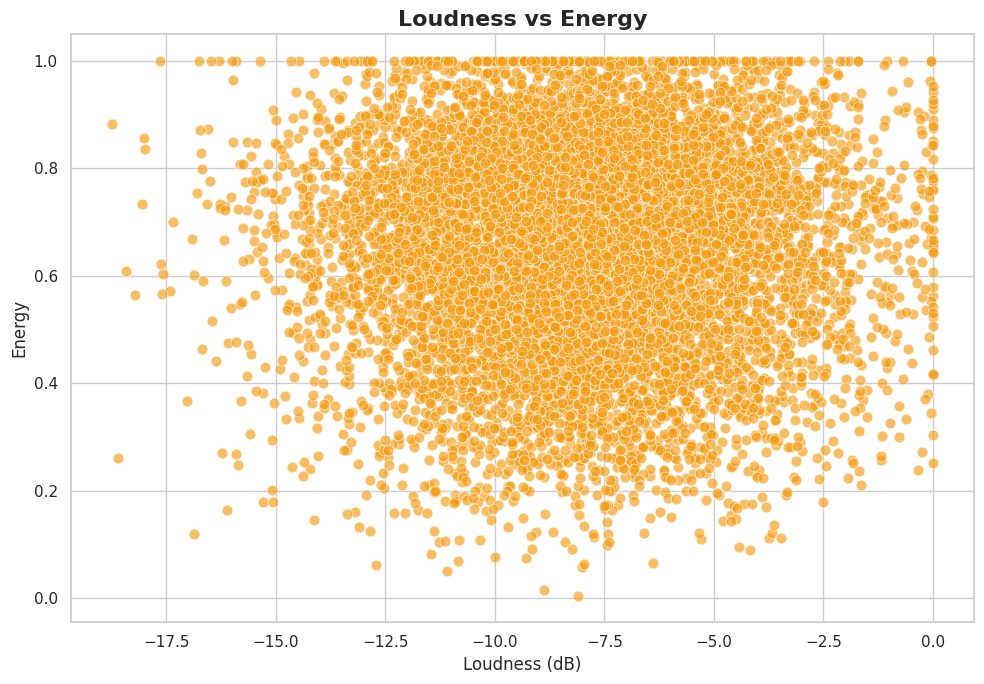

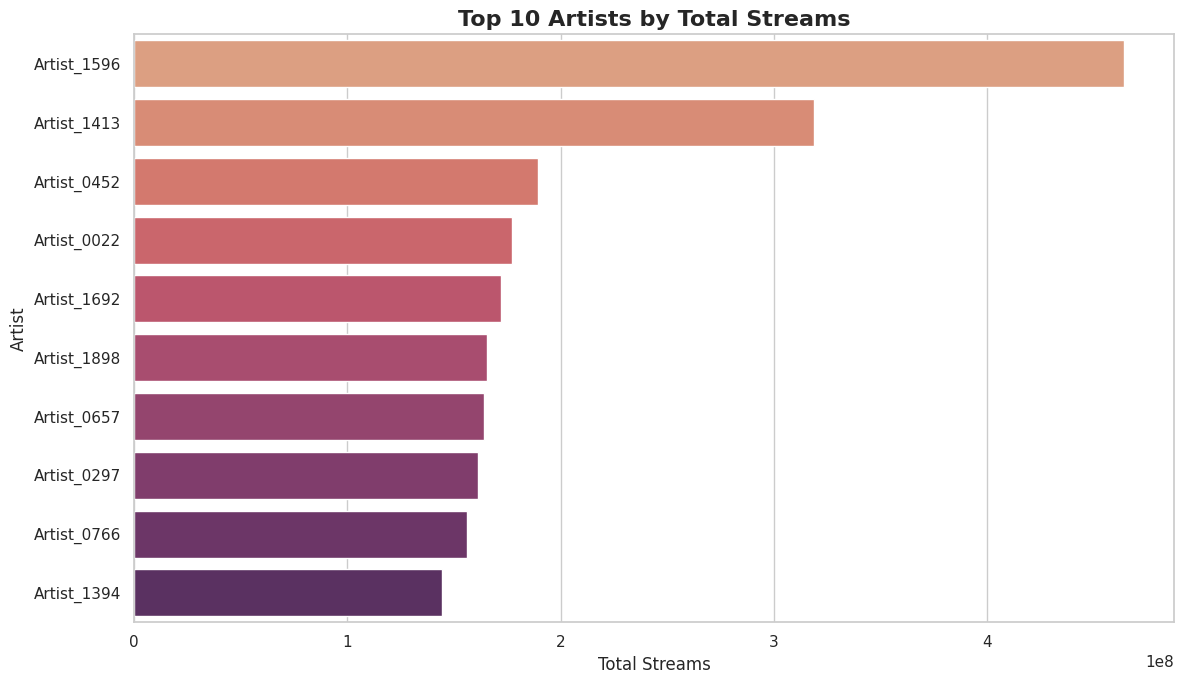

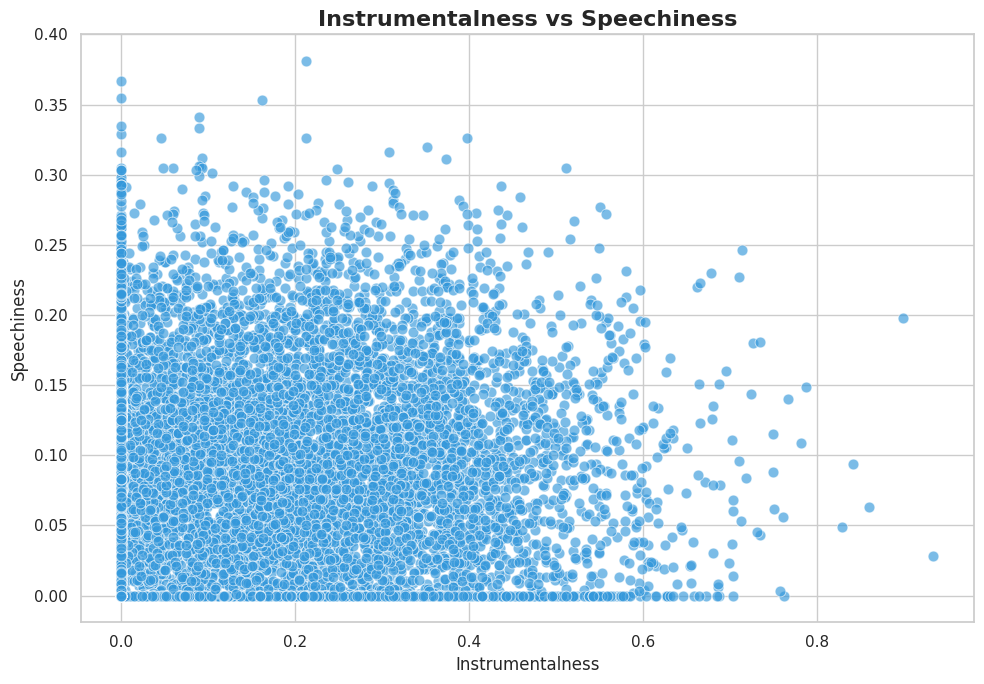

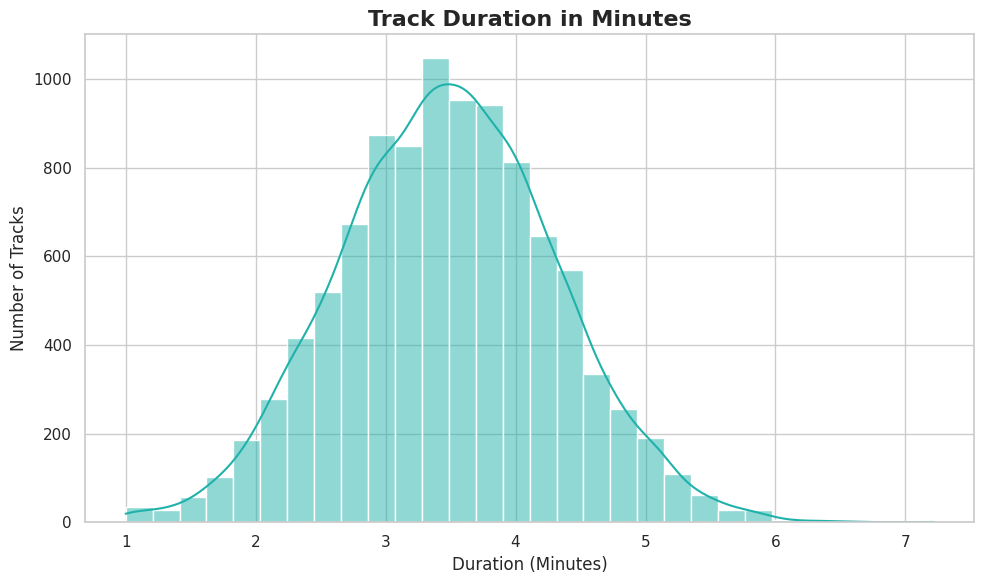


MUSIC DATASET VISUALIZATION COMPLETED

Total Tracks: 10000
Unique Artists: 1987
Unique Genres: 10
Release Year Range: 2010 to 2025
Total Streams: 24156848231
Average Streams per Track: 2415684.82

Viral Status Counts:
viral
0    6395
1    3605
Name: count, dtype: Int64

All available visualizations have been generated.


In [12]:

# ============================================================
# MUSIC STREAMING DATASET - COMPLETE DATA VISUALIZATION
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------
# If df is already loaded, this section will use your existing df.
# Otherwise, uncomment the appropriate line below.

# df = pd.read_csv("/kaggle/input/your-dataset-name/music.csv")
# df = pd.read_csv("/content/music.csv")

if 'df' not in globals():
    raise NameError(
        "Please load your CSV dataset into a DataFrame named df first."
    )

print("=" * 70)
print("MUSIC STREAMING DATASET - EXPLORATORY DATA ANALYSIS")
print("=" * 70)

print("\nDataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Rows:", df.duplicated().sum())

# ------------------------------------------------------------
# 2. DATA CLEANING
# ------------------------------------------------------------

df = df.copy()

# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Convert numeric columns to numeric data types
numeric_cols = [
    'release_year', 'duration_sec', 'danceability', 'energy',
    'valence', 'tempo_bpm', 'acousticness', 'instrumentalness',
    'speechiness', 'liveness', 'loudness_db', 'streams'
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Standardize viral labels where possible
if 'viral' in df.columns:
    df['viral'] = df['viral'].astype('string').str.strip()

print("\nDataset Shape After Removing Duplicates:", df.shape)

# ------------------------------------------------------------
# 3. SET COLOR PALETTES
# ------------------------------------------------------------

sns.set_theme(style="whitegrid", context="notebook")

palette = sns.color_palette("husl", 12)
genre_palette = sns.color_palette("Set2", 12)
feature_palette = sns.color_palette("Spectral", 12)

# ------------------------------------------------------------
# 4. MISSING VALUES VISUALIZATION
# ------------------------------------------------------------

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=missing.index,
        y=missing.values,
        hue=missing.index,
        palette="magma",
        legend=False
    )
    plt.title("Missing Values by Column", fontsize=16, weight="bold")
    plt.xlabel("Columns")
    plt.ylabel("Missing Value Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("\nNo missing values found.")

# ------------------------------------------------------------
# 5. CORRELATION HEATMAP
# ------------------------------------------------------------

available_numeric = df.select_dtypes(include=np.number).columns.tolist()

if len(available_numeric) >= 2:
    corr = df[available_numeric].corr()

    plt.figure(figsize=(14, 10))
    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        linewidths=0.5,
        square=False
    )
    plt.title("Correlation Heatmap of Music Features",
              fontsize=17, weight="bold")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 6. DISTRIBUTION OF NUMERIC FEATURES
# ------------------------------------------------------------

distribution_cols = [
    'duration_sec', 'danceability', 'energy', 'valence',
    'tempo_bpm', 'acousticness', 'instrumentalness',
    'speechiness', 'liveness', 'loudness_db', 'streams'
]

distribution_cols = [
    col for col in distribution_cols if col in df.columns
]

if distribution_cols:
    rows = int(np.ceil(len(distribution_cols) / 3))

    fig, axes = plt.subplots(
        rows, 3, figsize=(18, 5 * rows)
    )
    axes = np.array(axes).reshape(-1)

    for i, col in enumerate(distribution_cols):
        values = df[col].dropna()

        if len(values) > 0:
            sns.histplot(
                values,
                kde=True,
                color=palette[i % len(palette)],
                ax=axes[i]
            )
            axes[i].set_title(f"Distribution of {col}", weight="bold")
            axes[i].set_xlabel(col)
            axes[i].set_ylabel("Frequency")

    for j in range(len(distribution_cols), len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(
        "Distribution of Music Features",
        fontsize=19, weight="bold", y=1.01
    )
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 7. BOX PLOTS FOR OUTLIER ANALYSIS
# ------------------------------------------------------------

box_cols = [
    'duration_sec', 'danceability', 'energy', 'valence',
    'tempo_bpm', 'acousticness', 'instrumentalness',
    'speechiness', 'liveness', 'loudness_db'
]

box_cols = [col for col in box_cols if col in df.columns]

if box_cols:
    rows = int(np.ceil(len(box_cols) / 2))
    fig, axes = plt.subplots(rows, 2, figsize=(15, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for i, col in enumerate(box_cols):
        sns.boxplot(
            x=df[col],
            color=palette[i % len(palette)],
            ax=axes[i]
        )
        axes[i].set_title(f"Outlier Analysis: {col}", weight="bold")

    for j in range(len(box_cols), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 8. TOP 10 ARTISTS BY NUMBER OF TRACKS
# ------------------------------------------------------------

if 'artist' in df.columns:
    artist_counts = df['artist'].value_counts().head(10)

    if not artist_counts.empty:
        plt.figure(figsize=(12, 7))
        sns.barplot(
            x=artist_counts.values,
            y=artist_counts.index,
            hue=artist_counts.index,
            palette="viridis",
            legend=False
        )
        plt.title("Top 10 Artists by Track Count",
                  fontsize=16, weight="bold")
        plt.xlabel("Number of Tracks")
        plt.ylabel("Artist")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 9. TOP 10 GENRES BY NUMBER OF TRACKS
# ------------------------------------------------------------

if 'genre' in df.columns:
    genre_counts = df['genre'].value_counts().head(10)

    if not genre_counts.empty:
        plt.figure(figsize=(12, 7))
        sns.barplot(
            x=genre_counts.values,
            y=genre_counts.index,
            hue=genre_counts.index,
            palette="Set2",
            legend=False
        )
        plt.title("Top 10 Music Genres by Track Count",
                  fontsize=16, weight="bold")
        plt.xlabel("Number of Tracks")
        plt.ylabel("Genre")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 10. TOP 10 TRACKS BY STREAMS
# ------------------------------------------------------------

if {'track_name', 'streams'}.issubset(df.columns):
    top_tracks = df.nlargest(10, 'streams').dropna(subset=['streams'])

    if not top_tracks.empty:
        plt.figure(figsize=(13, 7))
        sns.barplot(
            data=top_tracks,
            x='streams',
            y='track_name',
            hue='track_name',
            palette="rocket",
            legend=False
        )
        plt.title("Top 10 Most Streamed Tracks",
                  fontsize=16, weight="bold")
        plt.xlabel("Streams")
        plt.ylabel("Track Name")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 11. STREAMS BY GENRE
# ------------------------------------------------------------

if {'genre', 'streams'}.issubset(df.columns):
    genre_streams = (
        df.groupby('genre', observed=True)['streams']
        .mean()
        .dropna()
        .sort_values(ascending=False)
        .head(10)
    )

    if not genre_streams.empty:
        plt.figure(figsize=(12, 7))
        sns.barplot(
            x=genre_streams.values,
            y=genre_streams.index,
            hue=genre_streams.index,
            palette="coolwarm",
            legend=False
        )
        plt.title("Top 10 Genres by Average Streams",
                  fontsize=16, weight="bold")
        plt.xlabel("Average Streams")
        plt.ylabel("Genre")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 12. RELEASE YEAR TREND
# ------------------------------------------------------------

if 'release_year' in df.columns:
    yearly_tracks = (
        df.groupby('release_year', observed=True)
        .size()
        .sort_index()
    )

    if not yearly_tracks.empty:
        plt.figure(figsize=(14, 6))
        plt.plot(
            yearly_tracks.index,
            yearly_tracks.values,
            marker='o',
            linewidth=2.5,
            color='#6A5ACD'
        )
        plt.fill_between(
            yearly_tracks.index,
            yearly_tracks.values,
            alpha=0.2,
            color='#9370DB'
        )
        plt.title("Number of Tracks Released per Year",
                  fontsize=16, weight="bold")
        plt.xlabel("Release Year")
        plt.ylabel("Number of Tracks")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 13. AVERAGE AUDIO FEATURES BY GENRE
# ------------------------------------------------------------

audio_features = [
    'danceability', 'energy', 'valence', 'acousticness',
    'instrumentalness', 'speechiness', 'liveness'
]

if 'genre' in df.columns:
    available_audio = [c for c in audio_features if c in df.columns]

    if available_audio:
        genre_audio = (
            df.groupby('genre', observed=True)[available_audio]
            .mean()
        )

        # Display at most 12 genres to keep the chart readable
        genre_audio = genre_audio.head(12)

        if not genre_audio.empty:
            plt.figure(figsize=(14, 8))
            sns.heatmap(
                genre_audio,
                annot=True,
                fmt=".2f",
                cmap="YlGnBu",
                linewidths=0.5
            )
            plt.title("Average Audio Features Across Genres",
                      fontsize=16, weight="bold")
            plt.xlabel("Audio Features")
            plt.ylabel("Genre")
            plt.tight_layout()
            plt.show()

# ------------------------------------------------------------
# 14. DANCEABILITY VS ENERGY
# ------------------------------------------------------------

if {'danceability', 'energy'}.issubset(df.columns):
    plot_df = df[['danceability', 'energy']].dropna()

    if not plot_df.empty:
        plt.figure(figsize=(10, 7))
        sns.scatterplot(
            data=plot_df,
            x='danceability',
            y='energy',
            color='#E74C3C',
            alpha=0.65,
            s=60
        )
        plt.title("Danceability vs Energy",
                  fontsize=16, weight="bold")
        plt.xlabel("Danceability")
        plt.ylabel("Energy")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 15. VALENCE VS DANCEABILITY
# ------------------------------------------------------------

if {'valence', 'danceability'}.issubset(df.columns):
    plot_df = df[['valence', 'danceability']].dropna()

    if not plot_df.empty:
        plt.figure(figsize=(10, 7))
        sns.scatterplot(
            data=plot_df,
            x='valence',
            y='danceability',
            color='#16A085',
            alpha=0.65,
            s=60
        )
        plt.title("Musical Positivity vs Danceability",
                  fontsize=16, weight="bold")
        plt.xlabel("Valence (Musical Positivity)")
        plt.ylabel("Danceability")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 16. TEMPO VS ENERGY
# ------------------------------------------------------------

if {'tempo_bpm', 'energy'}.issubset(df.columns):
    plot_df = df[['tempo_bpm', 'energy']].dropna()

    if not plot_df.empty:
        plt.figure(figsize=(10, 7))
        sns.scatterplot(
            data=plot_df,
            x='tempo_bpm',
            y='energy',
            color='#8E44AD',
            alpha=0.65,
            s=60
        )
        plt.title("Tempo vs Energy",
                  fontsize=16, weight="bold")
        plt.xlabel("Tempo (BPM)")
        plt.ylabel("Energy")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 17. STREAMS VS AUDIO FEATURES
# ------------------------------------------------------------

if 'streams' in df.columns:
    stream_features = [
        'danceability', 'energy', 'valence',
        'tempo_bpm', 'acousticness', 'loudness_db'
    ]

    stream_features = [
        c for c in stream_features if c in df.columns
    ]

    if stream_features:
        rows = int(np.ceil(len(stream_features) / 2))
        fig, axes = plt.subplots(rows, 2, figsize=(15, 5 * rows))
        axes = np.array(axes).reshape(-1)

        for i, col in enumerate(stream_features):
            sns.scatterplot(
                data=df,
                x=col,
                y='streams',
                color=palette[i % len(palette)],
                alpha=0.6,
                ax=axes[i]
            )
            axes[i].set_title(f"Streams vs {col}", weight="bold")

        for j in range(len(stream_features), len(axes)):
            axes[j].set_visible(False)

        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 18. VIRAL VS NON-VIRAL TRACKS
# ------------------------------------------------------------

if 'viral' in df.columns:
    viral_counts = df['viral'].fillna('Unknown').value_counts()

    if not viral_counts.empty:
        plt.figure(figsize=(8, 6))
        plt.pie(
            viral_counts.values,
            labels=viral_counts.index.astype(str),
            autopct='%1.1f%%',
            startangle=90,
            colors=sns.color_palette("Set3", len(viral_counts)),
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
        )
        plt.title("Viral vs Non-Viral Track Distribution",
                  fontsize=16, weight="bold")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 19. AUDIO FEATURES BY VIRAL STATUS
# ------------------------------------------------------------

if 'viral' in df.columns:
    viral_features = [
        'danceability', 'energy', 'valence',
        'tempo_bpm', 'acousticness', 'streams'
    ]

    viral_features = [
        c for c in viral_features if c in df.columns
    ]

    if viral_features:
        rows = int(np.ceil(len(viral_features) / 2))
        fig, axes = plt.subplots(rows, 2, figsize=(15, 5 * rows))
        axes = np.array(axes).reshape(-1)

        for i, col in enumerate(viral_features):
            sns.boxplot(
                data=df,
                x='viral',
                y=col,
                hue='viral',
                palette="Set2",
                legend=False,
                ax=axes[i]
            )
            axes[i].set_title(f"{col} by Viral Status", weight="bold")
            axes[i].set_xlabel("Viral Status")

        for j in range(len(viral_features), len(axes)):
            axes[j].set_visible(False)

        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 20. DURATION DISTRIBUTION BY GENRE
# ------------------------------------------------------------

if {'genre', 'duration_sec'}.issubset(df.columns):
    top_genres = df['genre'].value_counts().head(10).index
    duration_df = df[df['genre'].isin(top_genres)]

    if not duration_df.empty:
        plt.figure(figsize=(14, 7))
        sns.boxplot(
            data=duration_df,
            x='genre',
            y='duration_sec',
            hue='genre',
            palette="Pastel1",
            legend=False
        )
        plt.title("Track Duration Distribution by Genre",
                  fontsize=16, weight="bold")
        plt.xlabel("Genre")
        plt.ylabel("Duration (Seconds)")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 21. LOUDNESS VS ENERGY
# ------------------------------------------------------------

if {'loudness_db', 'energy'}.issubset(df.columns):
    plot_df = df[['loudness_db', 'energy']].dropna()

    if not plot_df.empty:
        plt.figure(figsize=(10, 7))
        sns.scatterplot(
            data=plot_df,
            x='loudness_db',
            y='energy',
            color='#F39C12',
            alpha=0.65,
            s=60
        )
        plt.title("Loudness vs Energy",
                  fontsize=16, weight="bold")
        plt.xlabel("Loudness (dB)")
        plt.ylabel("Energy")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 22. TOP ARTISTS BY TOTAL STREAMS
# ------------------------------------------------------------

if {'artist', 'streams'}.issubset(df.columns):
    artist_streams = (
        df.groupby('artist', observed=True)['streams']
        .sum()
        .dropna()
        .sort_values(ascending=False)
        .head(10)
    )

    if not artist_streams.empty:
        plt.figure(figsize=(12, 7))
        sns.barplot(
            x=artist_streams.values,
            y=artist_streams.index,
            hue=artist_streams.index,
            palette="flare",
            legend=False
        )
        plt.title("Top 10 Artists by Total Streams",
                  fontsize=16, weight="bold")
        plt.xlabel("Total Streams")
        plt.ylabel("Artist")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 23. INSTRUMENTALNESS VS SPEECHINESS
# ------------------------------------------------------------

if {'instrumentalness', 'speechiness'}.issubset(df.columns):
    plot_df = df[['instrumentalness', 'speechiness']].dropna()

    if not plot_df.empty:
        plt.figure(figsize=(10, 7))
        sns.scatterplot(
            data=plot_df,
            x='instrumentalness',
            y='speechiness',
            color='#3498DB',
            alpha=0.65,
            s=60
        )
        plt.title("Instrumentalness vs Speechiness",
                  fontsize=16, weight="bold")
        plt.xlabel("Instrumentalness")
        plt.ylabel("Speechiness")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 24. TRACK DURATION IN MINUTES
# ------------------------------------------------------------

if 'duration_sec' in df.columns:
    duration_minutes = df['duration_sec'].dropna() / 60

    if not duration_minutes.empty:
        plt.figure(figsize=(10, 6))
        sns.histplot(
            duration_minutes,
            bins=30,
            kde=True,
            color='#20B2AA'
        )
        plt.title("Track Duration in Minutes",
                  fontsize=16, weight="bold")
        plt.xlabel("Duration (Minutes)")
        plt.ylabel("Number of Tracks")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 25. SUMMARY REPORT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MUSIC DATASET VISUALIZATION COMPLETED")
print("=" * 70)

print("\nTotal Tracks:", len(df))

if 'artist' in df.columns:
    print("Unique Artists:", df['artist'].nunique())

if 'genre' in df.columns:
    print("Unique Genres:", df['genre'].nunique())

if 'release_year' in df.columns:
    print("Release Year Range:",
          df['release_year'].min(), "to", df['release_year'].max())

if 'streams' in df.columns:
    print("Total Streams:", df['streams'].sum())
    print("Average Streams per Track:", round(df['streams'].mean(), 2))

if 'viral' in df.columns:
    print("\nViral Status Counts:")
    print(df['viral'].value_counts(dropna=False))

print("\nAll available visualizations have been generated.")


## Feature engineering

MUSIC STREAMING ML CLASSIFICATION

Dataset Shape: (10000, 17)

Columns: ['track_id', 'track_name', 'artist', 'genre', 'release_year', 'duration_sec', 'danceability', 'energy', 'valence', 'tempo_bpm', 'acousticness', 'instrumentalness', 'speechiness', 'liveness', 'loudness_db', 'streams', 'viral']

First Five Rows:


,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1



Dataset Shape After Cleaning: (10000, 17)

Viral Target Distribution:
viral
0    6395
1    3605
Name: count, dtype: int64

Target Label Mapping:
0 -> 0
1 -> 1

Input Feature Count: 14
Target Classes: ['0' '1']

Numeric Features: ['release_year', 'duration_sec', 'danceability', 'energy', 'valence', 'tempo_bpm', 'acousticness', 'instrumentalness', 'speechiness', 'liveness', 'loudness_db', 'streams']

Categorical Features: ['artist', 'genre']

Training Features Shape: (8000, 14)
Testing Features Shape: (2000, 14)
Training Samples: 8000
Testing Samples: 2000

Training Class Distribution:
0    5116
1    2884
Name: count, dtype: int64

Testing Class Distribution:
0    1279
1     721
Name: count, dtype: int64

TRAINING: Logistic Regression
Accuracy:  79.45%
Precision: 69.47%
Recall:    76.70%
F1 Score:  72.91%
ROC-AUC:   88.40%

TRAINING: Decision Tree
Accuracy:  77.85%
Precision: 66.20%
Recall:    78.78%
F1 Score:  71.94%
ROC-AUC:   81.67%

TRAINING: Random Forest
Accuracy:  79.30%
Precisio

,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%),ROC-AUC (%)
0,Gradient Boosting,83.25,77.34,75.73,76.52,91.12
1,Random Forest,79.30,66.42,86.13,75.00,88.51
2,Logistic Regression,79.45,69.47,76.70,72.91,88.40
3,Support Vector Machine,78.60,67.93,76.98,72.17,87.44
4,Extra Trees,73.15,59.39,80.72,68.43,82.41
5,Decision Tree,77.85,66.20,78.78,71.94,81.67
6,K-Nearest Neighbors,71.40,61.59,54.92,58.06,77.06



Failed Models: {'Hist Gradient Boosting': "Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array."}


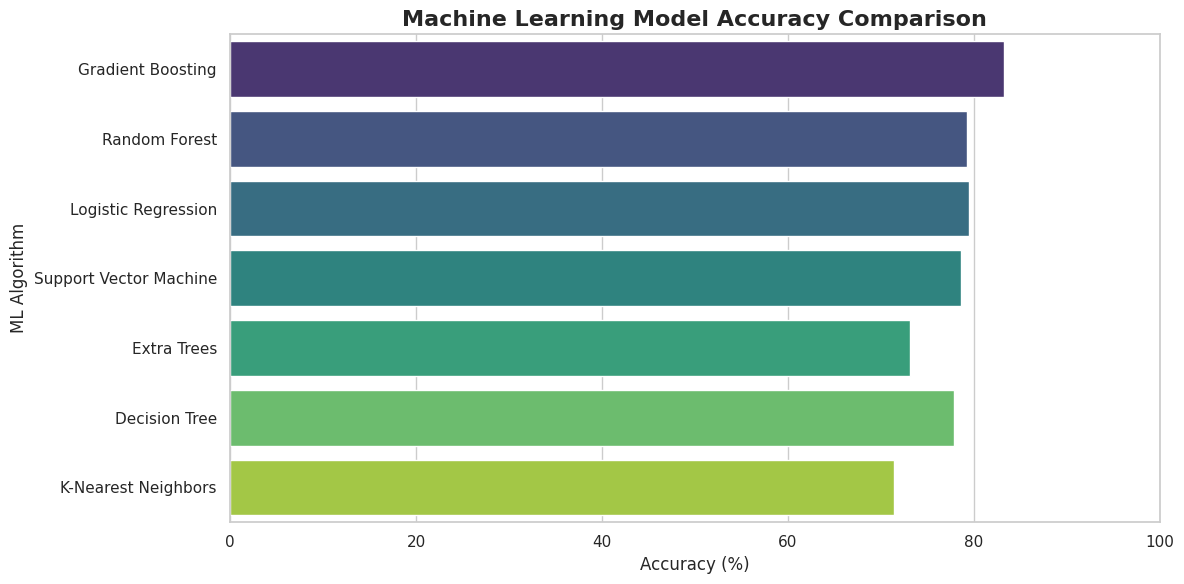

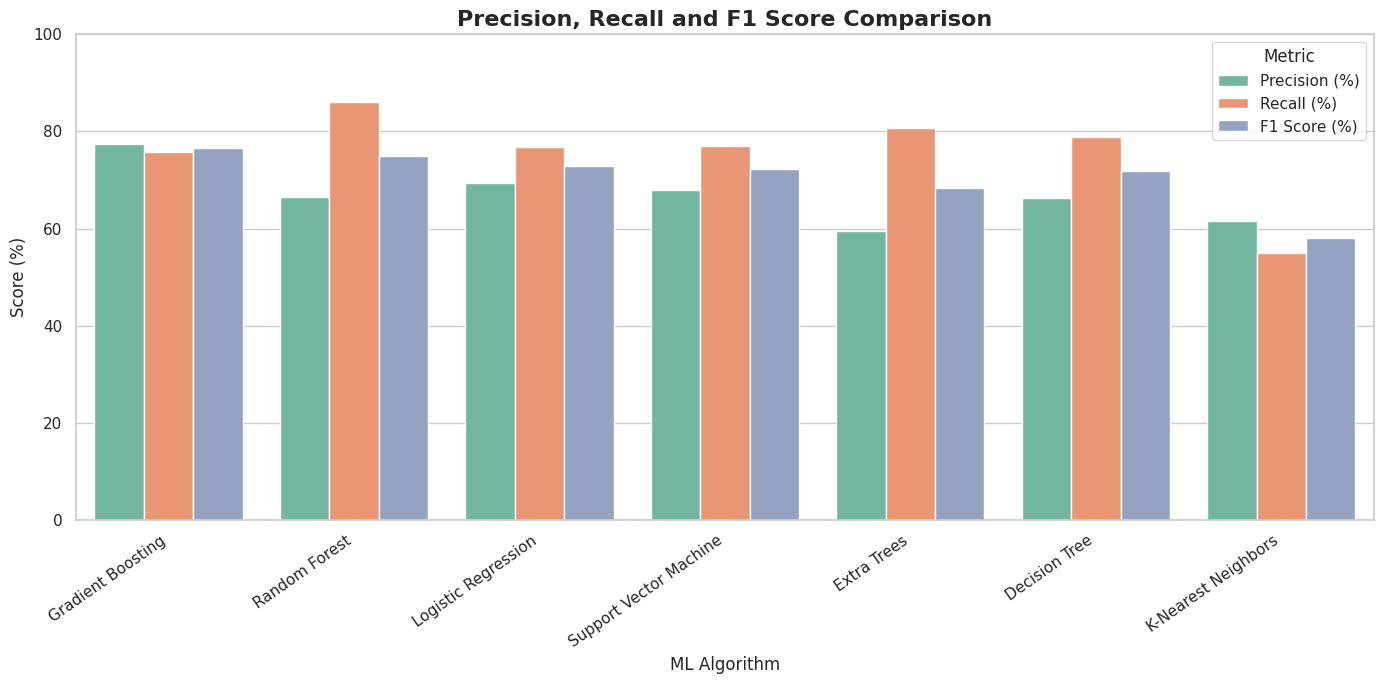

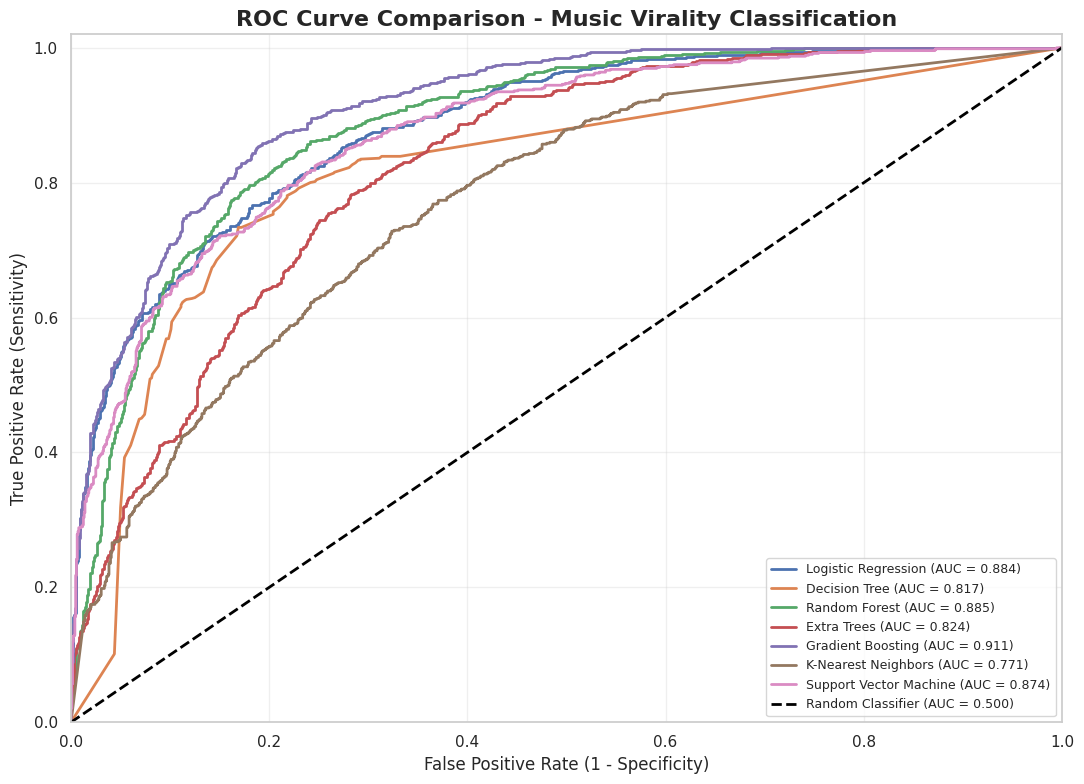


BEST MODEL BASED ON TEST ROC-AUC
Best Model: Gradient Boosting
Test ROC-AUC: 91.12%


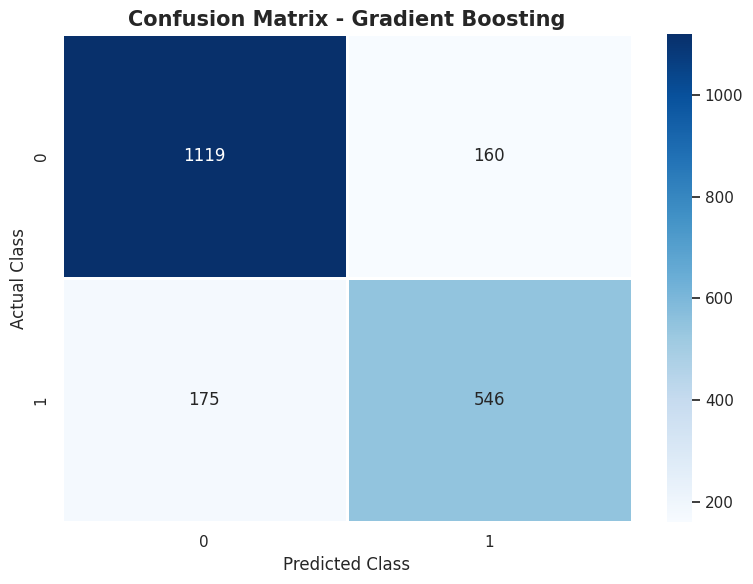


Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.87      0.87      1279
           1       0.77      0.76      0.77       721

    accuracy                           0.83      2000
   macro avg       0.82      0.82      0.82      2000
weighted avg       0.83      0.83      0.83      2000



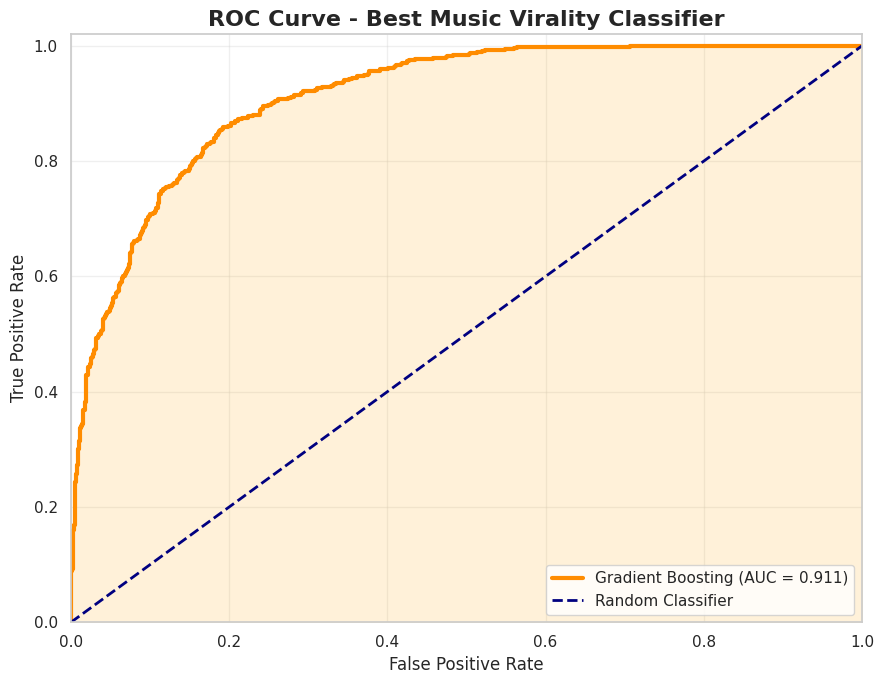


ROC Threshold Analysis (sample rows):


,Threshold,True Positive Rate,False Positive Rate
0,inf,0.0000,0.0000
49,0.8132,0.4230,0.0195
98,0.7400,0.5312,0.0438
147,0.6584,0.6144,0.0719
196,0.5743,0.7101,0.1063
245,0.4656,0.7836,0.1470
294,0.3349,0.8516,0.1876
343,0.2318,0.9071,0.2619
392,0.1408,0.9501,0.3761
441,0.0708,0.9931,0.5238



FINAL SUMMARY
Total Dataset Rows: 10000
Training Rows: 8000
Testing Rows: 2000
Input Features: 14
Algorithms Successfully Trained: 7
Best Model by Test ROC-AUC: Gradient Boosting
Best Model Accuracy: 83.25%
Best Model F1 Score: 76.52%
Best Model ROC-AUC: 0.9112

Machine learning classification pipeline completed.


In [13]:

# ================================================================
# MUSIC STREAMING DATASET: COMPLETE MACHINE LEARNING CLASSIFICATION
# Train-Test Split + Label Encoding + Multiple ML Algorithms
# Evaluation Metrics + Confusion Matrices + ROC Curves
# ================================================================

# STEP 1: IMPORT LIBRARIES
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ================================================================
# STEP 2: LOAD AND INSPECT DATA
# ================================================================

# Ensure your dataset is already loaded as df.
# Example:
# df = pd.read_csv("/kaggle/input/your-dataset/music.csv")

if "df" not in globals():
    raise NameError("Load your dataset into a DataFrame named df first.")

df = df.copy()

print("=" * 75)
print("MUSIC STREAMING ML CLASSIFICATION")
print("=" * 75)

print("\nDataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst Five Rows:")
display(df.head())

# ================================================================
# STEP 3: CLEAN DATA
# ================================================================

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Target column must exist
target = "viral"

if target not in df.columns:
    raise ValueError("The dataset must contain a 'viral' target column.")

# Remove rows with missing target labels
df = df.dropna(subset=[target]).copy()

# Normalize string target labels without creating new labels
if (pd.api.types.is_object_dtype(df[target])
        or isinstance(df[target].dtype, pd.StringDtype)):
    df[target] = df[target].astype(str).str.strip()

# Exclude empty target strings
df = df[df[target].astype(str).str.strip() != ""].copy()

print("\nDataset Shape After Cleaning:", df.shape)
print("\nViral Target Distribution:")
print(df[target].value_counts())

# This implementation evaluates binary classification and ROC curves.
if df[target].nunique() != 2:
    raise ValueError(
        f"'viral' must contain exactly 2 classes for this ROC pipeline. "
        f"Found: {df[target].nunique()} classes: "
        f"{df[target].unique().tolist()}"
    )

# ================================================================
# STEP 4: DEFINE FEATURES (X) AND TARGET (y)
# ================================================================

# Exclude identifiers and free-text track names to avoid
# unnecessary high-cardinality identifiers.
drop_cols = ["viral", "track_id", "track_name"]

X = df.drop(
    columns=[c for c in drop_cols if c in df.columns]
).copy()

y_original = df[target].copy()

# Convert numeric-looking columns to numeric where appropriate.
# Known numeric features are converted explicitly.
numeric_candidates = [
    "release_year", "duration_sec", "danceability", "energy",
    "valence", "tempo_bpm", "acousticness", "instrumentalness",
    "speechiness", "liveness", "loudness_db", "streams"
]

for col in numeric_candidates:
    if col in X.columns:
        X[col] = pd.to_numeric(X[col], errors="coerce")

# Remove columns that are entirely missing
all_missing_cols = X.columns[X.isna().all()].tolist()
if all_missing_cols:
    print("\nDropping entirely missing features:", all_missing_cols)
    X = X.drop(columns=all_missing_cols)

# Remove columns with a single unique nonmissing value
constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]

if constant_cols:
    print("Dropping constant features:", constant_cols)
    X = X.drop(columns=constant_cols)

if X.shape[1] == 0:
    raise ValueError("No usable input features remain after cleaning.")

# ================================================================
# STEP 5: LABEL ENCODE THE TARGET
# ================================================================

# LabelEncoder is suitable for the target classes.
# Input categorical features will use OneHotEncoder to avoid
# introducing a false numeric ordering between genres/artists.

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_original)

print("\nTarget Label Mapping:")
for encoded_value, class_name in enumerate(label_encoder.classes_):
    print(f"{class_name} -> {encoded_value}")

print("\nInput Feature Count:", X.shape[1])
print("Target Classes:", label_encoder.classes_)

# ================================================================
# STEP 6: IDENTIFY NUMERIC AND CATEGORICAL FEATURES
# ================================================================

numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

print("\nNumeric Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

# ================================================================
# STEP 7: TRAIN-TEST SPLIT
# ================================================================

# Split BEFORE fitting preprocessing transformations.
# Stratification keeps class proportions approximately balanced.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nTraining Class Distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting Class Distribution:")
print(pd.Series(y_test).value_counts().sort_index())

# ================================================================
# STEP 8: PREPROCESSING PIPELINE
# ================================================================

# Numeric features:
#   Missing values -> median
#   Scaling -> StandardScaler
#
# Categorical features:
#   Missing values -> most frequent category
#   Encoding -> OneHotEncoder
#
# Each model gets its own fitted preprocessing pipeline,
# fitted only on the training set.

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Compatibility with older and newer scikit-learn versions
try:
    one_hot = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )
except TypeError:
    one_hot = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", one_hot)
])

transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

# ================================================================
# STEP 9: DEFINE MACHINE LEARNING ALGORITHMS
# ================================================================

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5,
        weights="distance"
    ),

    "Support Vector Machine": SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=42
    )
}

# ================================================================
# STEP 10: TRAIN, PREDICT AND EVALUATE ALL MODELS
# ================================================================

results = []
trained_models = {}
predictions = {}
probabilities = {}
failures = {}

for name, algorithm in models.items():

    print("\n" + "=" * 75)
    print("TRAINING:", name)
    print("=" * 75)

    try:
        model_pipeline = Pipeline(steps=[
            ("preprocessor", preprocessor),
            ("classifier", algorithm)
        ])

        # Fit only using training data
        model_pipeline.fit(X_train, y_train)

        # Predictions on unseen test data
        y_pred = model_pipeline.predict(X_test)

        # Positive-class probabilities for ROC-AUC
        y_prob = model_pipeline.predict_proba(X_test)[:, 1]

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(
            y_test, y_pred, zero_division=0
        )
        recall = recall_score(
            y_test, y_pred, zero_division=0
        )
        f1 = f1_score(
            y_test, y_pred, zero_division=0
        )
        roc_auc = roc_auc_score(y_test, y_prob)

        results.append({
            "Model": name,
            "Accuracy (%)": accuracy * 100,
            "Precision (%)": precision * 100,
            "Recall (%)": recall * 100,
            "F1 Score (%)": f1 * 100,
            "ROC-AUC (%)": roc_auc * 100
        })

        trained_models[name] = model_pipeline
        predictions[name] = y_pred
        probabilities[name] = y_prob

        print(f"Accuracy:  {accuracy * 100:.2f}%")
        print(f"Precision: {precision * 100:.2f}%")
        print(f"Recall:    {recall * 100:.2f}%")
        print(f"F1 Score:  {f1 * 100:.2f}%")
        print(f"ROC-AUC:   {roc_auc * 100:.2f}%")

    except Exception as e:
        failures[name] = str(e)
        print("Model failed:", repr(e))

if not results:
    raise RuntimeError(
        "All models failed. Check feature data types, dataset size, "
        "missing values, and installed scikit-learn version."
    )

# ================================================================
# STEP 11: COMPARE MODEL PERFORMANCE
# ================================================================

results_df = pd.DataFrame(results).sort_values(
    by="ROC-AUC (%)",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 75)
print("MODEL COMPARISON TABLE")
print("=" * 75)

display(results_df.round(2))

print("\nFailed Models:", failures if failures else "None")

# ================================================================
# STEP 12: VISUALIZE MODEL ACCURACY
# ================================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Accuracy (%)",
    y="Model",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("Machine Learning Model Accuracy Comparison",
          fontsize=16, weight="bold")
plt.xlabel("Accuracy (%)")
plt.ylabel("ML Algorithm")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

# ================================================================
# STEP 13: COMPARE PRECISION, RECALL AND F1 SCORE
# ================================================================

comparison_metrics = results_df.melt(
    id_vars="Model",
    value_vars=["Precision (%)", "Recall (%)", "F1 Score (%)"],
    var_name="Metric",
    value_name="Score (%)"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=comparison_metrics,
    x="Model",
    y="Score (%)",
    hue="Metric",
    palette="Set2"
)

plt.title("Precision, Recall and F1 Score Comparison",
          fontsize=16, weight="bold")
plt.xlabel("ML Algorithm")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# ================================================================
# STEP 14: PLOT ROC CURVES FOR ALL SUCCESSFUL MODELS
# ================================================================

plt.figure(figsize=(11, 8))

for name, y_prob in probabilities.items():

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    model_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {model_auc:.3f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=2,
    color="black",
    label="Random Classifier (AUC = 0.500)"
)

plt.title("ROC Curve Comparison - Music Virality Classification",
          fontsize=16, weight="bold")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ================================================================
# STEP 15: SELECT BEST MODEL BY ROC-AUC
# ================================================================

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

best_pred = predictions[best_model_name]
best_prob = probabilities[best_model_name]

print("\n" + "=" * 75)
print("BEST MODEL BASED ON TEST ROC-AUC")
print("=" * 75)

print("Best Model:", best_model_name)
print(
    "Test ROC-AUC:",
    f"{roc_auc_score(y_test, best_prob) * 100:.2f}%"
)

# ================================================================
# STEP 16: CONFUSION MATRIX FOR BEST MODEL
# ================================================================

cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(f"Confusion Matrix - {best_model_name}",
          fontsize=15, weight="bold")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# ================================================================
# STEP 17: CLASSIFICATION REPORT
# ================================================================

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        best_pred,
        labels=[0, 1],
        target_names=[str(c) for c in label_encoder.classes_],
        zero_division=0
    )
)

# ================================================================
# STEP 18: ROC CURVE FOR THE BEST MODEL
# ================================================================

fpr, tpr, thresholds = roc_curve(y_test, best_prob)
best_auc = auc(fpr, tpr)

plt.figure(figsize=(9, 7))

plt.plot(
    fpr,
    tpr,
    color="darkorange",
    linewidth=3,
    label=f"{best_model_name} (AUC = {best_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    color="navy",
    linestyle="--",
    linewidth=2,
    label="Random Classifier"
)

plt.fill_between(
    fpr, tpr, alpha=0.15, color="orange"
)

plt.title("ROC Curve - Best Music Virality Classifier",
          fontsize=16, weight="bold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ================================================================
# STEP 19: ROC THRESHOLD ANALYSIS
# ================================================================

threshold_df = pd.DataFrame({
    "Threshold": thresholds,
    "True Positive Rate": tpr,
    "False Positive Rate": fpr
})

print("\nROC Threshold Analysis (sample rows):")
display(threshold_df.iloc[::max(1, len(threshold_df)//10)].round(4))

# ================================================================
# STEP 20: FINAL SUMMARY
# ================================================================

print("\n" + "=" * 75)
print("FINAL SUMMARY")
print("=" * 75)

print("Total Dataset Rows:", len(df))
print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))
print("Input Features:", X.shape[1])
print("Algorithms Successfully Trained:", len(trained_models))
print("Best Model by Test ROC-AUC:", best_model_name)
print(f"Best Model Accuracy: {accuracy_score(y_test, best_pred)*100:.2f}%")
print(f"Best Model F1 Score: {f1_score(y_test, best_pred)*100:.2f}%")
print(f"Best Model ROC-AUC: {best_auc:.4f}")

print("\nMachine learning classification pipeline completed.")


## thank you..pls upvote!!!!!